# 18 Normalverhaltensmodell je Station

Teil 5: Anomalien und Monitoring

**Worum es geht**
- Frage: Lässt sich eine Veränderung an einer Station aus den Tageswerten früh und wetterbereinigt erkennen, ohne Fehler-Labels?
- Idee: Jede Station lernt aus ihrem ersten Jahr, wie sie sich bei welcher Außentemperatur normalerweise verhält. Weicht sie mehrere Tage davon ab, gibt es einen Alarm.
- Das ist Früherkennung, keine Prognose: Das Modell sagt "die Station läuft seit ein paar Tagen anders als sonst bei diesem Wetter", nicht "sie fällt in vier Wochen aus".
- Ergebnis: je Station eine Kennlinie, Alarme, eine Prüfung gegen die Begehungen und eine Normkennzahl für den Vergleich mit der Flotte.

**Daten**
- liest: `data/processed/hast_tage.csv` (Tageswerte mit Außentemperatur), `data/raw/*Ergebnis_Optimierung_FW*.xlsx` (Begehungen), `data/raw/Zuordnung.xlsx` (Zuordnung Begehung zu Zählernummer)
- schreibt: `data/processed/normalmodell_stationen.csv`, `normalmodell_tage.csv`, `normalmodell_alarme.csv`, `normalmodell_wirkung.csv`, `normalmodell_treffer.csv`, `normalmodell.json`
- vorher ausführen: Notebook 10 (erzeugt `hast_tage.csv`)

**Code**
- Keine Abhängigkeit zu `src/`. Teile aus `src/load_begehungen.py` und `src/befundcodes.py` stehen als Kopie im Notebook (Abschnitt 3).

**Begriffe**

| Begriff | Bedeutung |
|---|---|
| Kanal | eine überwachte Messgröße. Hier zwei: Abkühlung (kWh/m³) und Wassermenge (Tagesvolumen) |
| Referenzzeitraum | das erste Jahr einer Station. Daraus lernt das Modell, was für sie normal ist |
| Erwartung | was die Station laut Modell bei der Außentemperatur des Tages liefern sollte |
| Residuum | gemessen minus erwartet. Positiv heißt: mehr als erwartet |
| Streuung s | typischer Abstand eines Referenztags zur Kennlinie |
| z-Wert | Residuum geteilt durch s (genauer: durch die wegen Autokorrelation vergrößerte Streuung, Abschnitt 5). z = 2 heißt: doppelt so weit weg wie an einem typischen Tag |
| CUSUM | Zähler, der Abweichungen über die Tage aufsummiert und kleine Ausreißer verzeiht (Abschnitt 7) |
| Alarm | der CUSUM überschreitet seine Schwelle |
| Kontrollgruppe | Stationen ohne Begehung im selben Zeitraum. Sie zeigen, wie oft es ohnehin Alarm gegeben hätte |

**Warum dieser Ansatz** (Befunde aus früheren Notebooks)

| Befund | Notebook | Folge hier |
|---|---|---|
| `n_actions > 0` ist bei 76 bis 80 % wahr, Freitext-Labels sind zu wenige | 07, 08, 14, ML-Klassifikator | Zielgröße ist ein Messwert, kein Label |
| Stationen bilden keine klaren Typen (Silhouette unter 0,25) | 07, 08, 10 | jede Station wird mit sich selbst verglichen |
| Begehungen verschieben das Niveau der Performance, nicht die Form der Kennlinie | 11, 12 | das Modell schaut auf das Niveau (kWh/m³) |
| Vorher/Nachher ohne Wetterbereinigung vermischt Jahreszeit und Wirkung | 02, 05 | Erwartung hängt von der Außentemperatur ab |
| Stundenwerte sind Momentaufnahmen | Check D2, 10 | Tageswerte aus Zählerständen |
| Kennlinienmonitor findet den Ventilfall, sonst knapp über Zufall | 13, 14 | dieselben Prüfsteine, damit es vergleichbar bleibt |

## 1 Setup und Parameter

- Alle Stellschrauben stehen in einer Zelle.
- Bedeutung und Startwerte erklärt die Tabelle unter der Zelle.

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams["figure.facecolor"] = "white"

ROOT = Path.cwd().resolve()
while not (ROOT / "notebooks").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

TAGE_PATH = ROOT / "data" / "processed" / "hast_tage.csv"
RAW = ROOT / "data" / "raw"
ZUORDNUNG_PATH = RAW / "Zuordnung.xlsx"
AUSGABE = ROOT / "data" / "processed"

#welche Tage ins Modell gehen
T_HEIZGRENZE = 15.0                          #nur Heiztage
IGNORIERTE_MARKIERUNGEN = {"wenig_stunden"}  #Markierungen aus NB 10, die hier nicht stören

#Kanäle: was das Modell überwacht
KANAELE = {
    "kwh_pro_m3": "Abkühlung (kWh/m³)",
    "log_volumen": "Wassermenge (Tagesvolumen)",
}

#Form der Kennlinie je Kanal (Abschnitt 5)
FORM_JE_KANAL = {"kwh_pro_m3": "gerade", "log_volumen": "klassen"}
KLASSENBREITE_K = 2.0     #Breite der Temperaturklassen
MIN_TAGE_JE_KLASSE = 8    #weniger Referenztage: Klasse fällt weg
AUTOKORRELATION_BERUECKSICHTIGEN = True   #Streuung größer, weil Folgetage sich ähneln
PHI_MAX = 0.8             #Korrektur höchstens Faktor 3

#Referenzzeitraum
REF_KALENDERTAGE = 365    #erstes Jahr einer Station = Referenz
ABSTAND_BEGEHUNG = 14     #Referenz endet so viele Tage vor der ersten Begehung
MIN_REF_TAGE = 60         #mindestens so viele Heiztage in der Referenz
MIN_REF_SPANNE_K = 8.0    #Temperaturspanne der Referenztage in K

#Test der Vorhersage
PRUEF_TAGE = 120          #Heiztage direkt nach der Referenz, vor jeder Begehung
MIN_PRUEF_TAGE = 20

#Alarm (CUSUM)
CUSUM_K = 0.5             #Toleranz je Tag, in Streuungen der Station
CUSUM_H = 5.0             #Alarmschwelle
CUSUM_MAX = 10.0          #Deckel des Zählers

#Abgleich mit den Begehungen
FENSTER_VOR = 7           #Alarm darf so viele Tage vor dem Termin liegen
FENSTER_NACH = 60         #... und so viele danach
MIN_TAGE_IM_FENSTER = 5   #Heiztage im Fenster, damit eine Station alarmieren kann
KONTROLL_VORLAUF = 60     #Kontrollstation ohne eigene Begehung so lange vorher
MIN_KONTROLLEN = 5        #weniger Kontrollstationen: Fall wird nicht bewertet
WIRKUNG_TAGE = 30         #Heiztage vor/nach der Begehung für die Wirkung
MIN_WIRKUNG_TAGE = 10
WIRKUNG_ABSTAND = 7       #Tage direkt um die Begehung bleiben draußen
WIRKUNG_MAX_TAGE = 365    #höchstens so weit vor/nach der Begehung suchen

#Flottenvergleich
T_NORM = 5.0              #Normtemperatur in °C
AKTUELL_TAGE = 60         #letzte Heiztage für den aktuellen Stand
RHO_C = 1.15              #kWh je m³ und K (wie NB 10)

#bekannter Fall
BEISPIEL = 68956351                          #Ventil drei Jahre offen
BEISPIEL_DATUM = pd.Timestamp("2024-09-09")  #Begehung mit Stellmotortausch
SEED = 42

#Darstellung (Farben wie NB 10)
FARBE_KANAL = {"kwh_pro_m3": "#2a78d6", "log_volumen": "#c74b12"}
FARBE_BEGANGEN, FARBE_KONTROLLE = "#4a3aa7", "#1baf7a"
TINTE, TINTE_LEISE, GITTER, ACHSE, FLAECHE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#f1f0ec"


def stil(ax):
    """Zurueckhaltende Achsen: nur links/unten, feines Gitter (wie NB 06)."""
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(ACHSE)
    ax.tick_params(colors=TINTE_LEISE, labelsize=9)
    ax.grid(color=GITTER, linewidth=0.6)
    ax.set_axisbelow(True)


def anzeige(kanal, werte):
    """Werte eines Kanals in lesbaren Einheiten: das Volumen aus dem Logarithmus zurueck in m³."""
    werte = np.asarray(werte, dtype=float)
    return np.exp(werte) if kanal == "log_volumen" else werte


def prozent(log_differenz):
    """Differenz zweier Logarithmen als Prozentaenderung, z. B. 0,1 -> +10,5 %."""
    return 100 * (np.exp(log_differenz) - 1)

**Was die Zelle macht**
- lädt Pakete und sucht den Projektordner (nach oben, bis `notebooks/` auftaucht)
- legt alle Schwellen und Fenster an einer Stelle fest. Zum Ausprobieren nur hier ändern und neu laufen lassen
- `anzeige()` rechnet das logarithmierte Volumen zurück in m³, `prozent()` macht aus einer Log-Differenz eine Prozentänderung

**Stellschrauben** (alles Startwerte)

| Parameter | Startwert | Warum | Wenn man ihn ändert |
|---|---|---|---|
| `T_HEIZGRENZE` | 15 °C | darüber fast nur Warmwasser, kWh/m³ hängt kaum noch am Wetter | höher: mehr Tage, aber Übergangstage verbiegen die Kennlinie |
| `IGNORIERTE_MARKIERUNGEN` | `wenig_stunden` | Begründung in Abschnitt 2 | `set()` = genau die Tage, die Notebook 10 `nutzbar` nennt |
| `FORM_JE_KANAL` | Abkühlung `gerade`, Wassermenge `klassen` | passt zum Bild in Abschnitt 2 (Begründung in Abschnitt 5) | `gerade` für die Wassermenge erzeugt Scheinalarme in Kälteperioden |
| `KLASSENBREITE_K` | 2 K | bildet Krümmung ab, rund 20 bis 30 Referenztage je Klasse | schmaler: genauer, aber jede Stützstelle wackliger |
| `MIN_TAGE_JE_KLASSE` | 8 | Median aus weniger Tagen ist zu unsicher | |
| `AUTOKORRELATION_BERUECKSICHTIGEN` | `True` | Folgetage ähneln sich, ohne Korrektur viel mehr Fehlalarme (Abschnitt 5) | `False`: empfindlicher, deutlich mehr Fehlalarme |
| `PHI_MAX` | 0,8 | begrenzt die Korrektur auf höchstens das Dreifache der Streuung | |
| `REF_KALENDERTAGE` | 365 | ein Jahr enthält kalte und milde Heiztage | kürzer: mehr überwachte Zeit, Kennlinie an wenigen Temperaturen gelernt |
| `ABSTAND_BEGEHUNG` | 14 Tage | Puffer, falls vorher schon verstellt wurde oder das Datum ungenau ist | |
| `MIN_REF_TAGE` | 60 | darunter wird die Kennlinie unsicher | höher: weniger Stationen, stabilere Kennlinien |
| `MIN_REF_SPANNE_K` | 8 K | bei fast gleichem Wetter keine Steigung schätzbar | |
| `CUSUM_K` | 0,5 | Lehrbuchwert für eine Verschiebung um eine Streuung s | kleiner: findet kleinere Verschiebungen, mehr Fehlalarme |
| `CUSUM_H` | 5 | Lehrbuchwert zu k = 0,5 (Abschnitt 7) | größer: weniger Fehlalarme, spätere Alarme |
| `CUSUM_MAX` | 10 | nach Rückkehr zum Normalzustand nach höchstens 20 Heiztagen wieder bei null | |
| `FENSTER_VOR` / `FENSTER_NACH` | 7 / 60 Tage | Begehungen fast alle im September, Heizperiode beginnt danach | länger: mehr Treffer, aber auch die Kontrollgruppe trifft öfter |
| `KONTROLL_VORLAUF` | 60 Tage | Kontrollstation mit eigener Begehung kurz vorher könnte deswegen alarmieren | |
| `WIRKUNG_TAGE` | 30 Heiztage | genug für einen stabilen Median, kurz genug gegen andere Veränderungen | |
| `T_NORM` | 5 °C | typischer Heiztag, bei fast allen Stationen mitten in den Referenzdaten | |
| `RHO_C` | 1,15 | Umrechnung kWh/m³ in Kelvin Spreizung (Spreizung = Vorlauf minus Rücklauf), wie in Notebook 10 | |

**Beim Ausprobieren**
- Fenster und Schwellen nicht so lange drehen, bis die Begehungen in Abschnitt 11 gut getroffen werden.
- Sonst misst Abschnitt 11 nur noch, wie gut die Schwellen an diese Begehungen angepasst sind (dasselbe Problem wie der nachträglich gewählte Split in Notebook 14).

## 2 Tageswerte laden

- Grundlage ist `hast_tage.csv` aus Notebook 10: eine Zeile je Station und Tag.
- Tagesenergie und Tagesvolumen kommen aus den Zählerständen (Stand um Mitternacht minus Stand der Mitternacht davor). Die Tagesmitteltemperatur kommt von der DWD-Station Kitzingen.
- Drei Entscheidungen, begründet unter der Zelle: nur Heiztage, `wenig_stunden` stört hier nicht, Volumen wird logarithmiert.

In [2]:
if not TAGE_PATH.is_file():
    raise FileNotFoundError(f"{TAGE_PATH} fehlt - zuerst Notebook 10 ausfuehren")

tage = pd.read_csv(TAGE_PATH, parse_dates=["datum"])
tage["zaehler"] = tage["zaehler"].astype(int)
tage["grund"] = tage["grund"].fillna("").astype(str)


def stoert(grund):
    """True, wenn der Tag eine Markierung traegt, die fuer dieses Modell zaehlt."""
    marken = {g.strip() for g in grund.split(",") if g.strip()}
    return bool(marken - IGNORIERTE_MARKIERUNGEN)


tage["verwendbar"] = (~tage["grund"].map(stoert).astype(bool)
                      & tage["kwh_pro_m3"].notna()
                      & (tage["volumen_m3"] > 0)
                      & tage["t_mittel_c"].notna())
tage["heiztag"] = tage["t_mittel_c"] < T_HEIZGRENZE
tage["log_volumen"] = np.log(tage["volumen_m3"].where(tage["volumen_m3"] > 0))

modelltage = (tage[tage["verwendbar"] & tage["heiztag"]]
              .sort_values(["zaehler", "datum"]).reset_index(drop=True))

uebersicht = pd.DataFrame({
    "Tage": [len(tage), int(tage["heiztag"].sum())],
    "nutzbar laut NB 06": [int(tage["nutzbar"].sum()), int((tage["nutzbar"] & tage["heiztag"]).sum())],
    "verwendbar hier": [int(tage["verwendbar"].sum()), len(modelltage)],
}, index=["alle Tage", "nur Heiztage"])
display(uebersicht)
print(f"{modelltage['zaehler'].nunique()} Stationen mit verwendbaren Heiztagen, "
      f"{modelltage['datum'].min():%Y-%m-%d} bis {modelltage['datum'].max():%Y-%m-%d}")

,Tage,nutzbar laut NB 06,verwendbar hier
alle Tage,85983,62734,77051
nur Heiztage,56754,44630,54774


93 Stationen mit verwendbaren Heiztagen, 2021-11-02 bis 2025-06-09


**Was die Zelle macht**
- markiert jeden Tag als verwendbar: keine störende Markierung, kWh/m³ vorhanden, Volumen über null, Außentemperatur vorhanden
- für das Modell bleiben die verwendbaren Heiztage (`modelltage`)
- die Tabelle vergleicht mit `nutzbar` aus Notebook 10

**Warum nur Heiztage**
- An Heiztagen hängt der Betrieb stark an der Außentemperatur. Genau diesen Einfluss rechnet das Modell heraus.
- Im Sommer hängt kWh/m³ an Warmwasser und Zirkulation, viele Tage haben unter 5 kWh.
- Preis: Fehler, die nur im Sommer auffallen (Dauerzirkulation), sieht das Modell nicht.

**Warum `wenig_stunden` ignorieren**
- Notebook 10 markiert Tage mit weniger als 12 Stundenwerten, weil dort Streuungsmerkmale aus Stundenwerten kommen.
- Hier zählen nur kWh/m³ und Tagesvolumen aus den Zählerständen. Fehlende Stundenwerte dazwischen spielen keine Rolle.
- Betrifft vor allem die Tage vor November 2022 mit nur einem Wert pro Tag (Notebook 12).
- Alle anderen Markierungen bleiben gültig.

**Warum das Volumen logarithmiert**
- Ein großes Haus zieht an einem kalten Tag 10 m³, ein kleines 1 m³. Im Logarithmus wird aus "0,5 m³ mehr" ein "10 % mehr".
- Abweichungen großer und kleiner Häuser werden dadurch vergleichbar. Den Anschlusswert braucht das Modell nicht.

**Ergebnis**
- 85.983 Tage insgesamt, davon 56.754 Heiztage.
- Verwendbare Heiztage: 54.774 hier gegen 44.630 `nutzbar` laut Notebook 10. Der Unterschied sind Tage, die nur wegen `wenig_stunden` markiert waren.
- 93 Stationen mit verwendbaren Heiztagen, 02.11.2021 bis 09.06.2025.

### 2.1 Welche Form hat der Zusammenhang mit dem Wetter?

- Abschnitt 5 lernt je Station eine Kennlinie: erwarteter Wert abhängig von der Außentemperatur. Hier wird geprüft, welche Form sie braucht.
- Jede Station wird um ihren eigenen Median verschoben. So bleibt nur die Änderung innerhalb einer Station.
- Gezeigt: je 1-K-Klasse der Median und das Band der mittleren 50 % der Tage, Klassen mit unter 50 Tagen fallen weg. Die gestrichelte Linie verbindet ersten und letzten Punkt.
- Wassermenge auf logarithmischer Achse als Vielfaches des Stationsmedians.

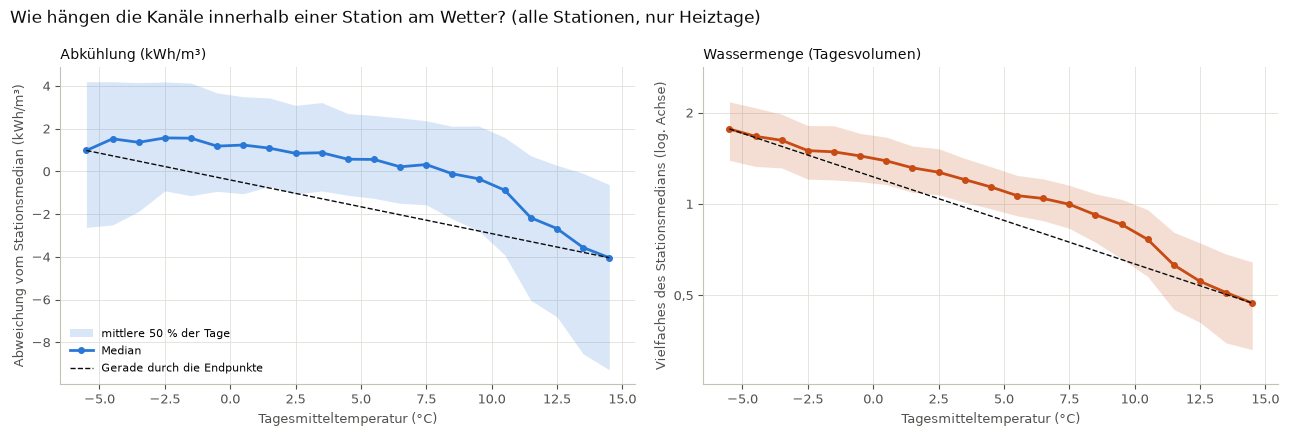

In [3]:
klassen = np.arange(np.floor(modelltage["t_mittel_c"].min()), T_HEIZGRENZE + 1)
klasse = pd.cut(modelltage["t_mittel_c"], klassen)


def formprofil(kanal):
    """Median und mittlere 50 % je 1-K-Klasse, jede Station um ihren eigenen Median verschoben."""
    zentriert = modelltage[kanal] - modelltage.groupby("zaehler")[kanal].transform("median")
    g = zentriert.groupby(klasse, observed=True)
    profil = pd.DataFrame({"n": g.size(), "p25": g.quantile(0.25), "p50": g.median(), "p75": g.quantile(0.75)})
    profil = profil[profil["n"] >= 50]
    profil["t"] = [iv.mid for iv in profil.index]
    return profil.reset_index(drop=True)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, (kanal, titel) in zip(axes, KANAELE.items()):
    p = formprofil(kanal)
    umrechnen = np.exp if kanal == "log_volumen" else (lambda w: w)
    farbe = FARBE_KANAL[kanal]
    if kanal == "log_volumen":
        ax.set_yscale("log")
    ax.fill_between(p["t"], umrechnen(p["p25"]), umrechnen(p["p75"]), color=farbe, alpha=0.18, linewidth=0,
                    label="mittlere 50 % der Tage")
    ax.plot(p["t"], umrechnen(p["p50"]), color=farbe, linewidth=2, marker="o", markersize=4, label="Median")
    if len(p) >= 2:
        gerade = np.interp(p["t"], p["t"].iloc[[0, -1]], p["p50"].iloc[[0, -1]])
        ax.plot(p["t"], umrechnen(gerade), color=TINTE, linestyle="--", linewidth=1,
                label="Gerade durch die Endpunkte")
    if kanal == "log_volumen":
        vielfaches = [0.25, 0.5, 1, 2, 4]
        ax.set_yticks(vielfaches, [f"{v:g}".replace(".", ",") for v in vielfaches])
        ax.minorticks_off()
        ax.set_ylim(np.exp(p["p25"].min()) / 1.3, np.exp(p["p75"].max()) * 1.3)
        ax.set_ylabel("Vielfaches des Stationsmedians (log. Achse)", fontsize=9, color=TINTE_LEISE)
    else:
        ax.set_ylabel("Abweichung vom Stationsmedian (kWh/m³)", fontsize=9, color=TINTE_LEISE)
    ax.set_title(titel, loc="left", fontsize=10, color=TINTE)
    ax.set_xlabel("Tagesmitteltemperatur (°C)", fontsize=9, color=TINTE_LEISE)
    stil(ax)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Wie hängen die Kanäle innerhalb einer Station am Wetter? (alle Stationen, nur Heiztage)",
             x=0.01, ha="left", color=TINTE)
fig.tight_layout()
plt.show()

**Wie man das Bild liest**
- Abkühlung (links): Liegt der Median nahe an der gestrichelten Geraden, reicht eine Gerade. Erwartung aus Notebook 05: etwa 0,6 bis 0,7 kWh/m³ weniger je Kelvin wärmer.
- Wassermenge (rechts): Krümmung erwartet. Steil bei Kälte, flach bei mildem Wetter wegen des Sockels aus Warmwasser und Zirkulation.
- Eine Gerade durch eine krumme Kurve liegt in Kälteperioden immer auf derselben Seite und erzeugt Scheinalarme in eine Richtung (Test mit synthetischen Daten beim Bau des Notebooks).
- Die Breite des Bandes ist die Schwankung, die das Wetter nicht erklärt. An den Rändern gibt es wenige Tage, dort ist die Linie unruhiger.

**Ergebnis**
- Die Form steht nur im Bild, nicht in Zahlen. Eingestellt ist Abkühlung `gerade`, Wassermenge `klassen`.
- Die gelernten Kennlinien (Abschnitt 5) zeigen: Die Wassermenge liegt bei 0 °C im Median um 85 % höher als bei 10 °C. Die Abkühlung ändert sich im Median nur um 0,32 kWh/m³ je Kelvin.

## 3 Begehungen laden

- Die Referenz einer Station soll vor ihrer ersten Begehung enden (Abschnitt 4). Sonst lernt das Modell den Zustand nach dem Eingriff als normal.
- In Abschnitt 10 und 11 sind die Begehungstermine der Prüfstein.
- Die Logik ist eine Kopie aus `src/load_begehungen.py` (Zuordnung zur Zählernummer über `Zuordnung.xlsx`) und `src/befundcodes.py` (Freitext zu mechanischem Befund), Stand 14.10.2026. So bekommen die Begehungen dieselben Zähler wie in Notebook 02, 13 und 14.
- Ändert sich dort etwas, muss es hier nachgezogen werden.

In [4]:
def adresse_norm(s):
    """Wie _normalize_address in src/load_data.py plus Tippfehler aus src/load_begehungen.py.

    Bewusst hier dupliziert (wie in NB 06), damit das Notebook eigenstaendig bleibt.
    """
    if not isinstance(s, str):
        return ""
    t = s.lower().strip().replace("ß", "ss")
    t = t.replace("ä", "ae").replace("ö", "oe").replace("ü", "ue")
    t = re.sub(r"\.", "", t)
    t = re.sub(r"str(asse)?\b", "strasse", t)
    t = re.sub(r"\s+", " ", t)
    t = re.sub(r"[^a-z0-9 \-]", "", t)
    t = re.sub(r"(\d)\s+([a-z])\b", r"\1\2", t)
    t = re.sub(r"\s*-\s*", "-", t)
    return t.strip().replace("fleiderstrasse", "fliederstrasse")


#Begehungstabelle: zweizeiliger Kopf, Daten ab Zeile 4
dateien = sorted(RAW.glob("*Ergebnis_Optimierung_FW*.xlsx"))
if not dateien:
    raise FileNotFoundError(f"keine Begehungstabelle unter {RAW}")
roh = pd.read_excel(dateien[0], sheet_name="Tabelle1", header=None)
kopf = [f"{a}|{b}" if pd.notna(b) else str(a) for a, b in zip(roh.iloc[0].ffill(), roh.iloc[1])]
koerper = roh.iloc[3:].reset_index(drop=True)


def spalte(muster):
    """Erste Spalte, deren Kopf das Muster enthaelt (wie position() in src/load_begehungen.py)."""
    for i, k in enumerate(kopf):
        if muster in k:
            return koerper.iloc[:, i]
    raise KeyError(f"Spalte {muster!r} nicht in der Begehungstabelle")


beg = pd.DataFrame({
    "datum": pd.to_datetime(spalte("Datum"), errors="coerce"),
    "strasse": spalte("Straßenname"),
    "hausnr": spalte("Hausnummer"),
    "kategorie": spalte("Kategorie"),
    "sonstiges": spalte("Sonstiges"),
})
beg = beg[beg["strasse"].notna()].copy()
beg["key"] = (beg["strasse"].astype(str).str.strip() + " "
              + beg["hausnr"].astype(str).str.strip()).map(adresse_norm)

#Zuordnung.xlsx: ein Blatt je Jahr, 2026 mit Straße und Hausnummer getrennt
teile = []
for blatt in pd.ExcelFile(ZUORDNUNG_PATH).sheet_names:
    z = pd.read_excel(ZUORDNUNG_PATH, sheet_name=blatt)
    sp = list(z.columns)
    if len(sp) > 3 and "Hausnr" in str(sp[2]):
        adresse = z[sp[1]].astype(str).str.strip() + " " + z[sp[2]].astype(str).str.strip()
    else:
        adresse = z[sp[2]]
    teile.append(pd.DataFrame({"zaehler": pd.to_numeric(z[sp[0]], errors="coerce"), "adresse": adresse}))
zuordnung = pd.concat(teile, ignore_index=True).dropna()
zuordnung["zaehler"] = zuordnung["zaehler"].astype(int)
zuordnung["key"] = zuordnung["adresse"].map(adresse_norm)
zuordnung = zuordnung[zuordnung["key"].str.len() > 3]

#je Adresse ein Zähler, bei Wechsel bevorzugt einer mit Tageswerten
mit_tageswerten = set(tage["zaehler"])
zaehler_je_adresse = {}
for key, gruppe in zuordnung.groupby("key"):
    kandidaten = sorted(set(gruppe["zaehler"]))
    mit_daten = [k for k in kandidaten if k in mit_tageswerten]
    zaehler_je_adresse[key] = mit_daten[0] if mit_daten else kandidaten[0]
beg["zaehler"] = beg["key"].map(zaehler_je_adresse)

/Users/seb/miniconda3/envs/projektseminar/lib/python3.11/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


In [5]:
#Kopie aus src/befundcodes.py: nur die fünf Kategorien für "mechanischer Befund" (NB 14)
#je Kategorie Treffermuster und Vetos davor/dahinter
VETO_FENSTER, VETO_FENSTER_DAVOR = 25, 20
MECHANISCHE_BEFUNDE = {
    "schmutzfaenger": ([r"schmutzfaenger", r"schmutzfilter", r"\bfilter\b"],
                       [r"^ (fast )?leer", r"^ sauber", r"^ passt", r"^ in ordnung"], []),
    "ventil_stellantrieb": ([r"regelventil", r"stellventil", r"stellmot\w*", r"stellant\w*",
                             r"\bamv\s*\d", r"\bventile?\b", r"regler schliesst nicht"],
                            [r"^ passt", r"^ in ordnung"], []),
    "pumpe": ([r"heizkreispumpe", r"rw pumpoe", r"rw pumpe", r"(?<!zirk )pumpe defekt",
               r"pumpe laeuft nicht"],
              [r"^ passt", r"^ in ordnung"], []),
    "zirkulation": ([r"zirk\w* pumpe", r"zirkulationspumpe", r"\bzirk\b", r"\bzirkulation",
                     r"fehlzirkulation"],
                    [r"^ passt", r"^ in ordnung"], [r"schwerkraft\s*$", r"natur\w*\s*$"]),
    "hydraulik_volumenstrom": ([r"volumenstrom", r"durchfluss", r"hydraulisch\w* abgleich",
                                r"hydraulik nicht richtig", r"druck ist zu niedrig",
                                r"hoher sekundaerdruck", r"eingeregelt"],
                               [r"^ passt", r"^ in ordnung"], []),
}
UMLAUTE = str.maketrans({"ä": "ae", "ö": "oe", "ü": "ue", "ß": "ss", "Ä": "ae", "Ö": "oe", "Ü": "ue"})


def normalisiere(text):
    """Kleinschreibung, Umlaute aufgeloest, Leerraum zusammengezogen."""
    if text is None or (isinstance(text, float) and pd.isna(text)):
        return ""
    return re.sub(r"\s+", " ", str(text).translate(UMLAUTE).lower()).strip()


def trifft(text, muster, veto_danach, veto_davor):
    """Trifft das Muster, ohne dass ein Veto direkt dahinter oder davor den Treffer aufhebt?"""
    for fund in re.finditer(muster, text):
        rechts = text[fund.end():fund.end() + VETO_FENSTER]
        links = text[max(0, fund.start() - VETO_FENSTER_DAVOR):fund.start()]
        if any(re.search(v, rechts) for v in veto_danach):
            continue
        if any(re.search(v, links) for v in veto_davor):
            continue
        return True
    return False


def mechanischer_befund(text):
    s = normalisiere(text)
    return any(trifft(s, m, danach, davor)
               for treffer, danach, davor in MECHANISCHE_BEFUNDE.values()
               for m in treffer)


beg["mechanisch"] = beg["sonstiges"].map(mechanischer_befund).astype(bool)
beg["datum"] = beg["datum"].dt.normalize()

#Termine je Zähler und Fälle: eine Zeile je Zähler und Termin
mit_termin = beg.dropna(subset=["datum", "zaehler"]).copy()
mit_termin["zaehler"] = mit_termin["zaehler"].astype(int)
termine = {zaehler: sorted(set(g["datum"])) for zaehler, g in mit_termin.groupby("zaehler")}
faelle_alle = (mit_termin.groupby(["zaehler", "datum"])
               .agg(kategorie=("kategorie", "first"), mechanisch=("mechanisch", "any"))
               .reset_index())

print(f"Begehungen in der Tabelle : {len(beg)}")
print(f"  mit Freitext            : {int((beg['sonstiges'].map(normalisiere) != '').sum())}")
print(f"  mit Datum               : {int(beg['datum'].notna().sum())}")
print(f"  mit Zaehlernummer       : {int(beg['zaehler'].notna().sum())}")
print(f"  mit Tageswerten (NB 06) : {int(beg['zaehler'].isin(mit_tageswerten).sum())}")
print(f"  mit mechanischem Befund : {int(beg['mechanisch'].sum())}")
print(f"Termine (Zaehler x Datum) : {len(faelle_alle)} an {faelle_alle['zaehler'].nunique()} Zaehlern")
display(beg["kategorie"].value_counts(dropna=False).to_frame("Begehungen"))
display(beg["datum"].dt.to_period("Q").value_counts().sort_index().to_frame("Begehungen je Quartal"))

Begehungen in der Tabelle : 66
  mit Freitext            : 57
  mit Datum               : 58
  mit Zaehlernummer       : 66
  mit Tageswerten (NB 06) : 59
  mit mechanischem Befund : 22
Termine (Zaehler x Datum) : 58 an 56 Zaehlern


,Begehungen
kategorie,
mittlere,36
viele,21
geringe,5
keine,4


,Begehungen je Quartal
datum,
2024Q3,36
2024Q4,17
2025Q1,1
2025Q3,4


**Was die beiden Zellen machen**
- lesen die Begehungstabelle mit zweizeiligem Kopf; Spalten werden über die Überschrift gefunden, weil sich das Layout zwischen Lieferungen geändert hat
- ordnen jeder Begehung über alle Jahresblätter von `Zuordnung.xlsx` eine Zählernummer zu; bei mehreren Zählern wird einer mit Tageswerten genommen
- kodieren den Freitext: mechanischer Befund = Schmutzfänger, Ventil/Stellantrieb, Pumpe, Zirkulation oder Hydraulik/Volumenstrom, mit Verneinungsprüfung ("Schmutzfänger fast leer" zählt nicht)
- `termine`: je Zähler die Begehungsdaten; `faelle_alle`: eine Zeile je Zähler und Termin

**Warum "mechanisch" extra**
- Notebook 14: Der Kennlinienmonitor trifft mechanische Eingriffe (10 von 19) deutlich besser als den Rest.
- Ein getauschter Stellmotor ändert die Hydraulik, eine verschobene Heizzeit die Tagesbilanz kaum. Gleiche Einteilung hält die Ergebnisse vergleichbar.

**Ergebnis**
- 66 Begehungen, davon 57 mit Freitext, 58 mit Datum, 59 mit Tageswerten, 22 mit mechanischem Befund. Das passt zu Notebook 02 und 14.
- 58 Termine an 56 Zählern. Mehrere Begehungen an einer Station zählen als getrennte Fälle und sind nicht unabhängig.
- Kategorie: 36 mittlere, 21 viele, 5 geringe, 4 keine Maßnahmen.
- Zeit: 36 im 3. Quartal 2024, 17 im 4. Quartal 2024, 1 im 1. Quartal 2025, 4 im 3. Quartal 2025.
- Tauschdaten der Zähler fehlen (Notebook 14, Abschnitt 8).

## 4 Referenzzeitraum je Station

- Jede Station bekommt als Referenz ihr erstes Jahr mit verwendbaren Heiztagen. Ein Jahr enthält kalte und milde Tage, die Kennlinie wird über den ganzen Temperaturbereich gelernt.
- Die Referenz endet spätestens 14 Tage vor der ersten Begehung. Sonst wäre die Wirkung unsichtbar. Kein Datenleck: Die ÜZ weiß im Betrieb, wann sie vor Ort war.
- Referenz heißt nicht gesund. Lief eine Station schon im ersten Jahr schlecht (Ventilfall 68956351), ist das ihr Normalzustand. Das Modell erkennt Veränderungen; dauerhaft schlechte Stationen zeigt Abschnitt 12.
- Nicht überwacht wird eine Station mit unter 60 Referenztagen, unter 8 K Temperaturspanne oder ohne Heiztage nach der Referenz.

In [6]:
zeilen = []
for zaehler, d in modelltage.groupby("zaehler"):
    start = d["datum"].min()
    ende = start + pd.Timedelta(days=REF_KALENDERTAGE)
    ende_grund = "ein Jahr"
    spaeter = [t for t in termine.get(zaehler, []) if t > start]
    if spaeter and spaeter[0] - pd.Timedelta(days=ABSTAND_BEGEHUNG) < ende:
        ende = spaeter[0] - pd.Timedelta(days=ABSTAND_BEGEHUNG)
        ende_grund = "vor Begehung"
    ref = d[(d["datum"] >= start) & (d["datum"] < ende)]
    spanne = ref["t_mittel_c"].max() - ref["t_mittel_c"].min() if len(ref) else 0.0
    nachher = int((d["datum"] >= ende).sum())
    if len(ref) < MIN_REF_TAGE:
        status = "zu wenige Referenztage"
    elif spanne < MIN_REF_SPANNE_K:
        status = "zu kleine Temperaturspanne"
    elif nachher == 0:
        status = "keine Tage nach der Referenz"
    else:
        status = "ok"
    zeilen.append({"zaehler": zaehler, "ref_start": start, "ref_ende": ende, "ende_grund": ende_grund,
                   "ref_tage": len(ref), "ref_spanne_k": spanne, "ueberwachte_tage": nachher,
                   "status": status})
referenz = pd.DataFrame(zeilen).set_index("zaehler")
stationen = referenz.index[referenz["status"] == "ok"].tolist()

display(referenz["status"].value_counts().to_frame("Stationen"))
ok = referenz.loc[stationen]
print(f"ueberwacht: {len(stationen)} Stationen")
print(f"  Referenz endet nach einem Jahr: {int((ok['ende_grund'] == 'ein Jahr').sum())}, "
      f"vor einer Begehung: {int((ok['ende_grund'] == 'vor Begehung').sum())}")
print(f"  Referenztage je Station: Median {ok['ref_tage'].median():.0f} "
      f"(min {ok['ref_tage'].min()}, max {ok['ref_tage'].max()})")
print(f"  Temperaturspanne der Referenz: Median {ok['ref_spanne_k'].median():.1f} K")
print(f"  ueberwachte Heiztage je Station: Median {ok['ueberwachte_tage'].median():.0f}")
display(ok["ref_ende"].dt.to_period("Q").value_counts().sort_index().to_frame("Referenz endet im Quartal"))

,Stationen
status,
ok,89
keine Tage nach der Referenz,4


ueberwacht: 89 Stationen
  Referenz endet nach einem Jahr: 69, vor einer Begehung: 20
  Referenztage je Station: Median 228 (min 84, max 240)
  Temperaturspanne der Referenz: Median 19.9 K
  ueberwachte Heiztage je Station: Median 241


,Referenz endet im Quartal
ref_ende,
2022Q4,43
2023Q1,1
2023Q2,1
2024Q3,29
2024Q4,12
2025Q1,3


**Was die Zelle macht**
- Start = erster verwendbarer Heiztag, Ende = ein Jahr später oder 14 Tage vor der ersten Begehung, je nachdem, was früher kommt
- zählt Referenztage, Temperaturspanne und überwachbare Tage danach
- `stationen` = Stationen mit Status `ok`; nur mit ihnen rechnet der Rest

**Ergebnis**
- 89 Stationen werden überwacht, 5 fallen heraus, weil nach der Referenz keine Tage mehr kommen.
- Referenz endet bei 70 Stationen nach einem Jahr, bei 19 vor einer Begehung.
- Je Station im Median 228 Referenztage (84 bis 240), Temperaturspanne 19,9 K, 241 überwachte Heiztage.
- Ende der Referenz: 43 Stationen im 4. Quartal 2022, 28 im 3. Quartal 2024, 12 im 4. Quartal 2024, 3 im 1. Quartal 2025, sonst einzeln. Das passt zu den zwei Ausbauwellen aus Notebook 00.

## 5 Das Modell: eine Kennlinie je Station und Kanal

- Aus den Referenztagen lernt das Modell, welchen Wert die Station bei welcher Tagesmitteltemperatur T hat. Diese Kennlinie liefert für jeden späteren Tag die Erwartung.
- Dazu je Kanal die Streuung s und die Autokorrelation (Begründungen unten).

**Zwei Formen, je Kanal wählbar** (`FORM_JE_KANAL`)

| Form | Wie | Gut für | Startwert für |
|---|---|---|---|
| `gerade` | Erwartung = a + b · T, Theil-Sen-Gerade | gerade Zusammenhänge | Abkühlung |
| `klassen` | Median der Referenztage je 2-K-Klasse, Punkte mit Linien verbunden | krumme Zusammenhänge | Wassermenge |

- Gerade: a = Erwartung bei 0 °C, b = Änderung je Kelvin wärmer.
- Klassenkennlinie: Klassen mit unter 8 Referenztagen fallen weg. Außerhalb des Referenzbereichs gilt der Wert der äußersten Klasse.

**Warum nicht immer die Klassenkennlinie**
- Jeder Punkt stammt aus nur 20 bis 30 Tagen und wackelt. Eine Gerade nutzt alle Tage für zwei Zahlen.
- Im Test mit synthetischen Daten: Gerade bei der (dort geraden) Abkühlung weniger Fehlalarme; bei der krummen Wassermenge zeigten mit der Geraden fast alle Fehlalarme nach unten.
- Die Abkühlungsgerade ist dieselbe Form wie in Notebook 05 und auf der ÜZ-Folie.

**Warum Theil-Sen**
- Theil-Sen = Median der Steigungen aller Tagespaare. Einzelne kaputte Tage (Zählersprung, Leerstand) ändern ihn kaum, anders als bei der üblichen Regression.
- Aus demselben Grund nimmt die Klassenkennlinie den Median je Klasse.

**Warum die Streuung s mit dem MAD**
- MAD = Median der Abstände zum Median. Mal 1,4826 entspricht er bei Normalverteilung der Standardabweichung, reagiert aber kaum auf Ausreißer.
- Jeder Tag wird in typischen Schwankungen dieser Station gemessen (z-Wert). Eine ruhige Station schlägt bei kleineren Abweichungen an als eine unruhige.

**Warum die Streuung wegen Autokorrelation vergrößert wird**
- Autokorrelation φ = wie stark die Abweichung heute die von morgen vorhersagt (0 = unabhängig, 1 = morgen wie heute). Gebäude sind träge, Wetterlagen halten an.
- Der CUSUM zählt jeden Tag als neue Information. Ohne Korrektur alarmierte im synthetischen Test über die Hälfte der Kontrollstationen in jedem Zweimonatsfenster.
- Korrektur: Streuung mal √((1 + φ) / (1 − φ)), bei φ = 0,5 etwa 1,7. Preis: kleine echte Verschiebungen brauchen länger bis zum Alarm.
- Abschalten mit `AUTOKORRELATION_BERUECKSICHTIGEN = False`.

In [7]:
def lerne_kennlinie(form, t, y):
    """Lernt aus Referenztagen die Kennlinie Temperatur -> erwarteter Wert.

    "gerade": Theil-Sen-Gerade (Median der Steigungen aller Tagespaare).
    "klassen": Median je Temperaturklasse an der mittleren Temperatur der Klasse.
    Hat die Referenz weniger als zwei brauchbare Klassen, wird ersatzweise die Gerade genommen.
    """
    t, y = np.asarray(t, dtype=float), np.asarray(y, dtype=float)
    if form == "klassen":
        tab = (pd.DataFrame({"klasse": np.floor(t / KLASSENBREITE_K), "t": t, "y": y})
               .groupby("klasse").agg(n=("y", "size"), t=("t", "median"), y=("y", "median")))
        tab = tab[tab["n"] >= MIN_TAGE_JE_KLASSE]
        if len(tab) >= 2:
            return {"form": "klassen", "stuetz_t": tab["t"].to_numpy(), "stuetz_y": tab["y"].to_numpy()}
    b, a, _, _ = stats.theilslopes(y, t)
    return {"form": "gerade", "a": a, "b": b}


def kennlinienwert(kennlinie, t):
    """Erwarteter Wert der Kennlinie bei Temperatur t."""
    t = np.asarray(t, dtype=float)
    if kennlinie["form"] == "gerade":
        return kennlinie["a"] + kennlinie["b"] * t
    return np.interp(t, kennlinie["stuetz_t"], kennlinie["stuetz_y"])


def robuste_streuung(r):
    """1,4826 * MAD: robust wie der Median, bei Normalverteilung gleich der Standardabweichung."""
    r = np.asarray(r, dtype=float)
    return 1.4826 * np.median(np.abs(r - np.median(r)))


def autokorrelation(rest):
    """Korrelation der Residuen zweier aufeinanderfolgender verwendbarer Heiztage."""
    if len(rest) < 3 or np.std(rest) == 0:
        return 0.0
    return float(np.corrcoef(rest[:-1], rest[1:])[0, 1])


def referenztage(zaehler):
    d = modelltage[modelltage["zaehler"] == zaehler]
    return d[(d["datum"] >= referenz.at[zaehler, "ref_start"]) & (d["datum"] < referenz.at[zaehler, "ref_ende"])]


modelle, zeilen = {}, []
for zaehler in stationen:
    ref = referenztage(zaehler)
    t = ref["t_mittel_c"].to_numpy()
    for kanal in KANAELE:
        y = ref[kanal].to_numpy()
        kennlinie = lerne_kennlinie(FORM_JE_KANAL[kanal], t, y)
        rest = y - kennlinienwert(kennlinie, t)
        s = max(robuste_streuung(rest), 1e-6)
        phi = autokorrelation(rest)
        phi_korrektur = min(max(phi, 0.0), PHI_MAX)
        faktor = np.sqrt((1 + phi_korrektur) / (1 - phi_korrektur)) if AUTOKORRELATION_BERUECKSICHTIGEN else 1.0
        modelle[(zaehler, kanal)] = {"kennlinie": kennlinie, "s": s, "s_eff": s * faktor}
        zeilen.append({"zaehler": zaehler, "kanal": kanal, "form": kennlinie["form"],
                       "b": kennlinie.get("b", np.nan),
                       "klassen": len(kennlinie.get("stuetz_t", [])) or np.nan,
                       "kalt_minus_mild": float(kennlinienwert(kennlinie, 0.0) - kennlinienwert(kennlinie, 10.0)),
                       "s": s, "autokorrelation": phi, "faktor": faktor})
parameter = pd.DataFrame(zeilen)

zusammenfassung = parameter.groupby("kanal").agg(
    Stationen=("zaehler", "size"),
    davon_gerade=("form", lambda f: int((f == "gerade").sum())),
    b_median=("b", "median"),
    klassen_median=("klassen", "median"),
    kalt_minus_mild_median=("kalt_minus_mild", "median"),
    anteil_kalt_hoeher=("kalt_minus_mild", lambda x: (x > 0).mean()),
    s_median=("s", "median"),
    autokorrelation_median=("autokorrelation", "median"),
    faktor_median=("faktor", "median"),
).reindex(list(KANAELE))
display(zusammenfassung.round(3))
km_vol = zusammenfassung.at["log_volumen", "kalt_minus_mild_median"]
s_vol = zusammenfassung.at["log_volumen", "s_median"]
print(f"Wassermenge: bei 0 °C im Median {prozent(km_vol):+.0f} % mehr Wasser als bei 10 °C, "
      f"typische Tagesstreuung rund {prozent(s_vol):.0f} %")

,Stationen,davon_gerade,b_median,klassen_median,kalt_minus_mild_median,anteil_kalt_hoeher,s_median,autokorrelation_median,faktor_median
kanal,,,,,,,,,
kwh_pro_m3,89,89,-0.317,NaN,3.173,0.764,2.461,0.682,2.299
log_volumen,89,0,NaN,8.0,0.617,0.921,0.203,0.590,1.970


Wassermenge: bei 0 °C im Median +85 % mehr Wasser als bei 10 °C, typische Tagesstreuung rund 22 %


**Was die Zelle macht**
- `lerne_kennlinie()` lernt Gerade oder Klassenkennlinie, `kennlinienwert()` liest die Erwartung ab
- je Station und Kanal: Kennlinie, Streuung s, Autokorrelation φ und Korrekturfaktor; gespeichert in `modelle`, als Tabelle in `parameter`

**Wie man die Tabelle liest**
- `davon_gerade`: Stationen mit Gerade. Bei der Wassermenge heißt ein Wert über 0: zu wenige Tage je Klasse, ersatzweise Gerade.
- `b_median`: Änderung der kWh/m³ je Kelvin wärmer (nur Gerade).
- `kalt_minus_mild_median`: Erwartung bei 0 °C minus bei 10 °C (Wassermenge in Log-Einheiten).
- `anteil_kalt_hoeher`: Anteil Stationen mit höherem Wert bei 0 °C als bei 10 °C. Eine Station, die bei Kälte weniger Wasser zieht, ist selbst ein Befund.
- `s_median`: typische Tagesschwankung um die Kennlinie; `faktor_median`: Vergrößerung wegen Autokorrelation.

**Ergebnis**
- Abkühlung: alle 89 Stationen mit Gerade. Steigung im Median −0,32 kWh/m³ je Kelvin, etwa halb so steil wie die −0,6 bis −0,7 aus Notebook 05 (dort über alle Stationen).
- Abkühlung: bei 0 °C im Median 3,17 kWh/m³ mehr als bei 10 °C, bei 76 % der Stationen ist der Wert bei Kälte höher. Streuung s im Median 2,46 kWh/m³.
- Wassermenge: alle 89 Stationen mit Klassenkennlinie (im Median 8 Stützpunkte). Bei 0 °C im Median 85 % mehr Wasser als bei 10 °C, bei 92 % der Stationen ist der Wert bei Kälte höher. Typische Tagesstreuung rund 22 %.
- Autokorrelation im Median 0,68 (Abkühlung) und 0,59 (Wassermenge). Die Streuung wird dadurch im Median um den Faktor 2,3 bzw. 2,0 vergrößert. Folgetage hängen also stark zusammen.

## 6 Wie gut ist die Vorhersage?

- Geprüft wird auf Tagen, die das Modell nicht kannte: die ersten bis zu 120 Heiztage nach der Referenz, vor jeder Begehung.
- Vergleich mit einem naiven Modell ohne Temperatur: immer der Median der Referenz.
- Skill = 1 − Fehler Modell / Fehler naiv (mittlerer absoluter Fehler). 0 = Temperatur bringt nichts, 0,5 = halber Fehler, negativ = schlechter als naiv.

,Stationen,Pruef_tage_median,fehler_modell_median,fehler_naiv_median,skill_median,anteil_skill_positiv
kanal,,,,,,
kwh_pro_m3,67,120.0,3.049,2.908,0.015,0.552
log_volumen,67,120.0,0.235,0.322,0.260,0.851


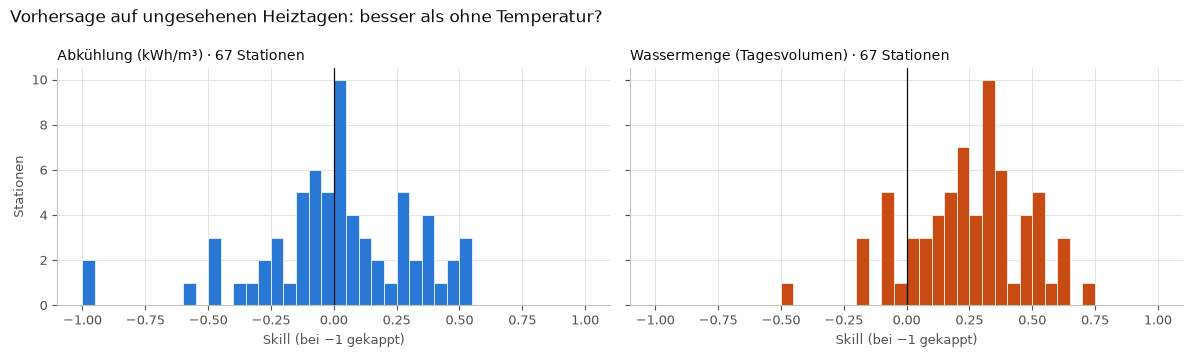

In [8]:
def erwartung(zaehler, kanal, t):
    """Erwarteter Wert eines Kanals bei Tagesmitteltemperatur t."""
    return kennlinienwert(modelle[(zaehler, kanal)]["kennlinie"], t)


zeilen = []
for zaehler in stationen:
    d = modelltage[modelltage["zaehler"] == zaehler]
    ref_ende = referenz.at[zaehler, "ref_ende"]
    pruef = d[d["datum"] >= ref_ende]
    spaeter = [t for t in termine.get(zaehler, []) if t >= ref_ende]
    if spaeter:
        pruef = pruef[pruef["datum"] < spaeter[0] - pd.Timedelta(days=FENSTER_VOR)]
    pruef = pruef.head(PRUEF_TAGE)
    if len(pruef) < MIN_PRUEF_TAGE:
        continue
    ref = referenztage(zaehler)
    for kanal in KANAELE:
        y = pruef[kanal].to_numpy()
        fehler_modell = np.mean(np.abs(y - erwartung(zaehler, kanal, pruef["t_mittel_c"])))
        fehler_naiv = np.mean(np.abs(y - ref[kanal].median()))
        zeilen.append({"zaehler": zaehler, "kanal": kanal, "tage": len(pruef),
                       "fehler_modell": fehler_modell, "fehler_naiv": fehler_naiv,
                       "skill": 1 - fehler_modell / fehler_naiv})
guete = pd.DataFrame(zeilen, columns=["zaehler", "kanal", "tage", "fehler_modell", "fehler_naiv", "skill"])

display(guete.groupby("kanal").agg(
    Stationen=("zaehler", "size"),
    Pruef_tage_median=("tage", "median"),
    fehler_modell_median=("fehler_modell", "median"),
    fehler_naiv_median=("fehler_naiv", "median"),
    skill_median=("skill", "median"),
    anteil_skill_positiv=("skill", lambda x: (x > 0).mean()),
).reindex(list(KANAELE)).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, (kanal, titel) in zip(axes, KANAELE.items()):
    w = guete.loc[guete["kanal"] == kanal, "skill"].clip(-1, 1)
    ax.hist(w, bins=np.linspace(-1, 1, 41), color=FARBE_KANAL[kanal], edgecolor="white", linewidth=0.5)
    ax.axvline(0, color=TINTE, linewidth=0.9)
    ax.set_title(f"{titel} · {len(w)} Stationen", loc="left", fontsize=10, color=TINTE)
    ax.set_xlabel("Skill (bei −1 gekappt)", fontsize=9, color=TINTE_LEISE)
    stil(ax)
axes[0].set_ylabel("Stationen", fontsize=9, color=TINTE_LEISE)
fig.suptitle("Vorhersage auf ungesehenen Heiztagen: besser als ohne Temperatur?", x=0.01, ha="left", color=TINTE)
fig.tight_layout()
plt.show()

**Was die Zelle macht**
- nimmt je Station die Heiztage nach der Referenz und hört 7 Tage vor der ersten Begehung auf
- rechnet Fehler von Modell und naivem Modell und daraus den Skill
- Stationen mit unter 20 solchen Tagen fehlen hier, werden aber überwacht (vor allem zweite Ausbauwelle, Referenz endet kurz vor Sommer 2024)

**Wie man das Ergebnis liest**
- Wassermenge-Fehler in Log-Einheiten: 0,15 heißt rund 15 % typische Abweichung.
- Negativer Skill einer Station: Entweder hat sie sich seit der Referenz verändert (selbst ein Befund), oder die Temperatur erklärt bei ihr nichts.

**Ergebnis**
- 67 Stationen geprüft, im Median 120 Prüftage.
- Wassermenge: Skill im Median 0,26, bei 85 % der Stationen positiv. Die Temperatur verbessert die Vorhersage klar.
- Abkühlung: Skill im Median 0,02, nur bei 55 % positiv. Die Temperatur bringt bei kWh/m³ auf neuen Tagen praktisch nichts. Das passt zur flachen Steigung in Abschnitt 5.

## 7 Abweichung und Alarm: der CUSUM

- Ein einzelner auffälliger Tag ist meist Zufall. Interessant ist, wenn die Station mehrere Tage in dieselbe Richtung abweicht.
- CUSUM (kumulierte Summe, Page 1954) als Kontostand: Jeden Tag wird der z-Wert eingezahlt und eine Gebühr k = 0,5 abgezogen. Das Konto fällt nicht unter null. Über der Schwelle h = 5 gibt es Alarm.
- Zwei Konten: S⁺ für Abweichungen nach oben, S⁻ nach unten.

**Beispiele mit k = 0,5 und h = 5**

| Was die Station tut | Was das Konto tut | Alarm |
|---|---|---|
| Zufall um null | Plus und Minus gleichen sich aus, Gebühr hält es bei null | keiner |
| jeden Tag 1 Streuung höher | wächst um 0,5 pro Tag | nach rund 10 Tagen |
| jeden Tag 2 Streuungen höher | wächst um 1,5 pro Tag | nach rund 4 Tagen |
| ein Tag z = +6, dann normal | springt auf 5,5, fällt wieder | ja |
| Ventilfall, z um +20 | sofort über der Schwelle | am ersten Tag |

**Warum nicht "Alarm, wenn z über 3"**
- Das reagiert auf jeden Einzeltag und übersieht kleine, dauerhafte Verschiebungen (jeden Tag z = 1).

**Was die Theorie verspricht**
- Bei unabhängigen, normalverteilten Tagen im Mittel ein Fehlalarm alle rund 465 Tage (beide Richtungen). Bei 150 bis 200 Heiztagen im Jahr etwa einer alle zwei bis drei Jahre je Kanal.
- Echte Tage sind nicht unabhängig. Die Korrektur aus Abschnitt 5 gleicht das nur ungefähr aus. Die echte Alarmrate misst Abschnitt 9, die Kontrollgruppe Abschnitt 11.

**Zwei Zusätze zum Lehrbuch**
- Ein Alarm je Abweichung: Ein neuer Alarm in dieselbe Richtung kommt erst, wenn das Konto zwischendurch bei null war.
- Deckel bei 10: Nach Rückkehr zum Normalzustand ist das Konto nach höchstens 20 Heiztagen wieder bei null.
- Gezählt wird nur über verwendbare Heiztage; Sommer und Lücken werden übersprungen, der Kontostand bleibt.

Zuerst ein Spielzeugbeispiel ohne echte Daten.

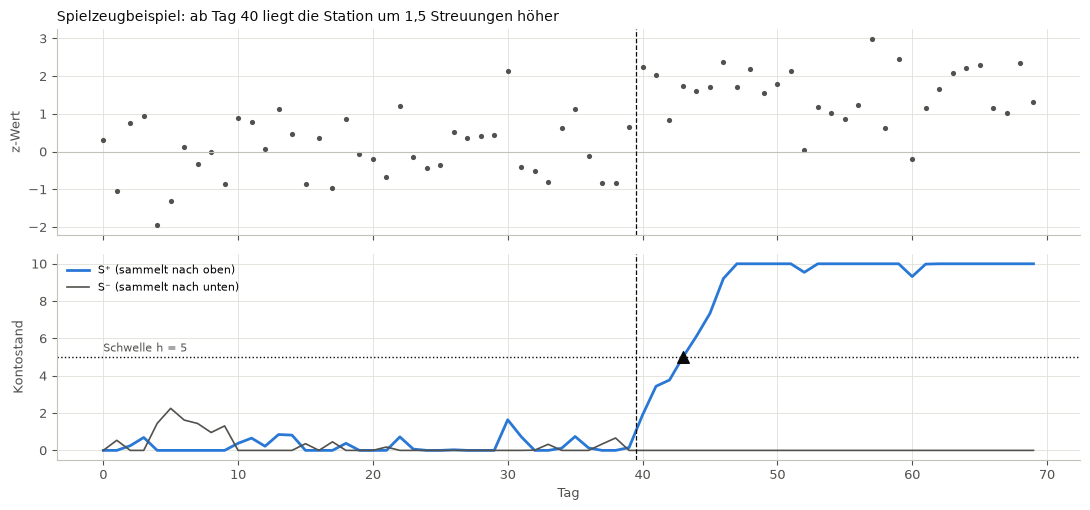

Alarm nach oben an Tag 43, Lauf begann an Tag 39 (5 Tage bis zum Alarm)


In [9]:
def cusum(z, k=CUSUM_K, h=CUSUM_H, deckel=CUSUM_MAX):
    """Zweiseitiger CUSUM ueber eine Folge von z-Werten (Page 1954).

    S+ sammelt Abweichungen nach oben, S- nach unten. Ein Alarm entsteht, wenn ein
    Konto h ueberschreitet; ein weiterer in dieselbe Richtung erst, wenn das Konto
    zwischendurch bei null war. Rueckgabe: S+ und S- je Tag und die Alarme als
    (Index, Richtung, Startindex). Der Startindex ist der erste Tag des Laufs, also
    die Schaetzung, wann die Veraenderung begann.
    """
    s_plus, s_minus = np.zeros(len(z)), np.zeros(len(z))
    sp = sm = 0.0
    an_plus = an_minus = False
    start_plus = start_minus = 0
    alarme = []
    for i, zi in enumerate(z):
        if sp == 0.0:
            start_plus = i
        if sm == 0.0:
            start_minus = i
        sp = min(max(0.0, sp + zi - k), deckel)
        sm = min(max(0.0, sm - zi - k), deckel)
        if sp == 0.0:
            an_plus = False
        if sm == 0.0:
            an_minus = False
        if sp > h and not an_plus:
            alarme.append((i, +1, start_plus))
            an_plus = True
        if sm > h and not an_minus:
            alarme.append((i, -1, start_minus))
            an_minus = True
        s_plus[i], s_minus[i] = sp, sm
    return s_plus, s_minus, alarme


#Beispiel: 40 normale Tage, danach jeden Tag 1,5 Streuungen höher
rng = np.random.default_rng(SEED)
z_spiel = rng.normal(0, 1, 70)
z_spiel[40:] += 1.5
sp_spiel, sm_spiel, alarme_spiel = cusum(z_spiel)
x_spiel = np.arange(len(z_spiel))

fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True)
axes[0].scatter(x_spiel, z_spiel, s=14, color=TINTE_LEISE, linewidths=0)
axes[0].axhline(0, color=ACHSE, linewidth=0.8)
axes[0].set_ylabel("z-Wert", fontsize=9, color=TINTE_LEISE)
axes[0].set_title("Spielzeugbeispiel: ab Tag 40 liegt die Station um 1,5 Streuungen höher",
                  loc="left", fontsize=10, color=TINTE)
axes[1].plot(x_spiel, sp_spiel, color=FARBE_KANAL["kwh_pro_m3"], linewidth=2, label="S⁺ (sammelt nach oben)")
axes[1].plot(x_spiel, sm_spiel, color=TINTE_LEISE, linewidth=1.2, label="S⁻ (sammelt nach unten)")
axes[1].axhline(CUSUM_H, color=TINTE, linestyle=":", linewidth=1)
axes[1].text(0, CUSUM_H + 0.3, f"Schwelle h = {CUSUM_H:g}", fontsize=8, color=TINTE_LEISE)
for i, richtung, start in alarme_spiel:
    s_wert = sp_spiel[i] if richtung > 0 else sm_spiel[i]
    axes[1].scatter(i, s_wert, marker="^" if richtung > 0 else "v", s=70, color=TINTE, zorder=3)
axes[1].set_ylabel("Kontostand", fontsize=9, color=TINTE_LEISE)
axes[1].set_xlabel("Tag", fontsize=9, color=TINTE_LEISE)
axes[1].legend(frameon=False, fontsize=8, loc="upper left")
for ax in axes:
    ax.axvline(39.5, color=TINTE, linestyle="--", linewidth=0.9)
    stil(ax)
fig.tight_layout()
plt.show()
for i, richtung, start in alarme_spiel:
    print(f"Alarm {'nach oben' if richtung > 0 else 'nach unten'} an Tag {i}, "
          f"Lauf begann an Tag {start} ({i - start + 1} Tage bis zum Alarm)")

**Wie man das Spielzeugbild liest**
- oben: z-Wert je Tag. Bis Tag 39 Zufall um null, ab Tag 40 (gestrichelt) im Mittel +1,5.
- unten: die beiden Konten. Ab Tag 40 wächst S⁺ um rund 1 pro Tag (1,5 − 0,5). Das Dreieck markiert den Alarm.
- Ergebnis laut Ausgabe: Alarm an Tag 43, Lauf begann an Tag 39. Der Laufbeginn ist die Schätzung, wann die Veränderung anfing.
- Danach bleibt S⁺ am Deckel und meldet keinen neuen Alarm.

### 7.1 Dieselbe Rechnung für eine echte Station

`verlauf_station()` macht für eine Station und beide Kanäle:
1. Erwartung aus der Kennlinie für jeden verwendbaren Heiztag
2. Residuum = gemessen − erwartet, z-Wert = Residuum / s
3. CUSUM über die Tage nach der Referenz
4. Alarme mit Datum, Richtung und geschätztem Beginn

In [10]:
def verlauf_station(zaehler):
    """Je Kanal und verwendbarem Heiztag: Erwartung, Residuum, z-Wert und CUSUM."""
    d = modelltage[modelltage["zaehler"] == zaehler]
    ref_ende = referenz.at[zaehler, "ref_ende"]
    teile, alarme_station = [], []
    for kanal in KANAELE:
        m = modelle[(zaehler, kanal)]
        v = pd.DataFrame({"zaehler": zaehler, "kanal": kanal,
                          "datum": d["datum"].to_numpy(),
                          "t_mittel_c": d["t_mittel_c"].to_numpy(),
                          "gemessen": d[kanal].to_numpy()})
        v["erwartet"] = erwartung(zaehler, kanal, v["t_mittel_c"])
        v["residuum"] = v["gemessen"] - v["erwartet"]
        v["z"] = v["residuum"] / m["s_eff"]
        v["referenz"] = v["datum"] < ref_ende
        v["s_plus"] = np.nan
        v["s_minus"] = np.nan
        ueberwacht_idx = v.index[~v["referenz"]]
        s_plus, s_minus, al = cusum(v.loc[ueberwacht_idx, "z"].to_numpy())
        v.loc[ueberwacht_idx, "s_plus"] = s_plus
        v.loc[ueberwacht_idx, "s_minus"] = s_minus
        daten = v.loc[ueberwacht_idx, "datum"].to_numpy()
        for i, richtung, start in al:
            alarme_station.append({"zaehler": zaehler, "kanal": kanal,
                                   "datum": pd.Timestamp(daten[i]), "richtung": richtung,
                                   "beginn": pd.Timestamp(daten[start]),
                                   "heiztage_bis_alarm": i - start + 1})
        teile.append(v)
    return pd.concat(teile, ignore_index=True), alarme_station

## 8 Der bekannte Fall 68956351

- Bei dieser Station stand das Ventil rund drei Jahre offen. Bei der Begehung am 09.09.2024 wurde der Stellmotor getauscht (nur im Freitext, Notebook 14).
- Ihre Referenz ist also der defekte Zustand: wenig Abkühlung, viel Wasser.
- Erwartet: vor der Reparatur ruhig; danach Abkühlung höher und Wassermenge niedriger, an den ersten Heiztagen.
- Im September gibt es nur vereinzelt Heiztage unter 15 °C, die meisten kommen ab Oktober.

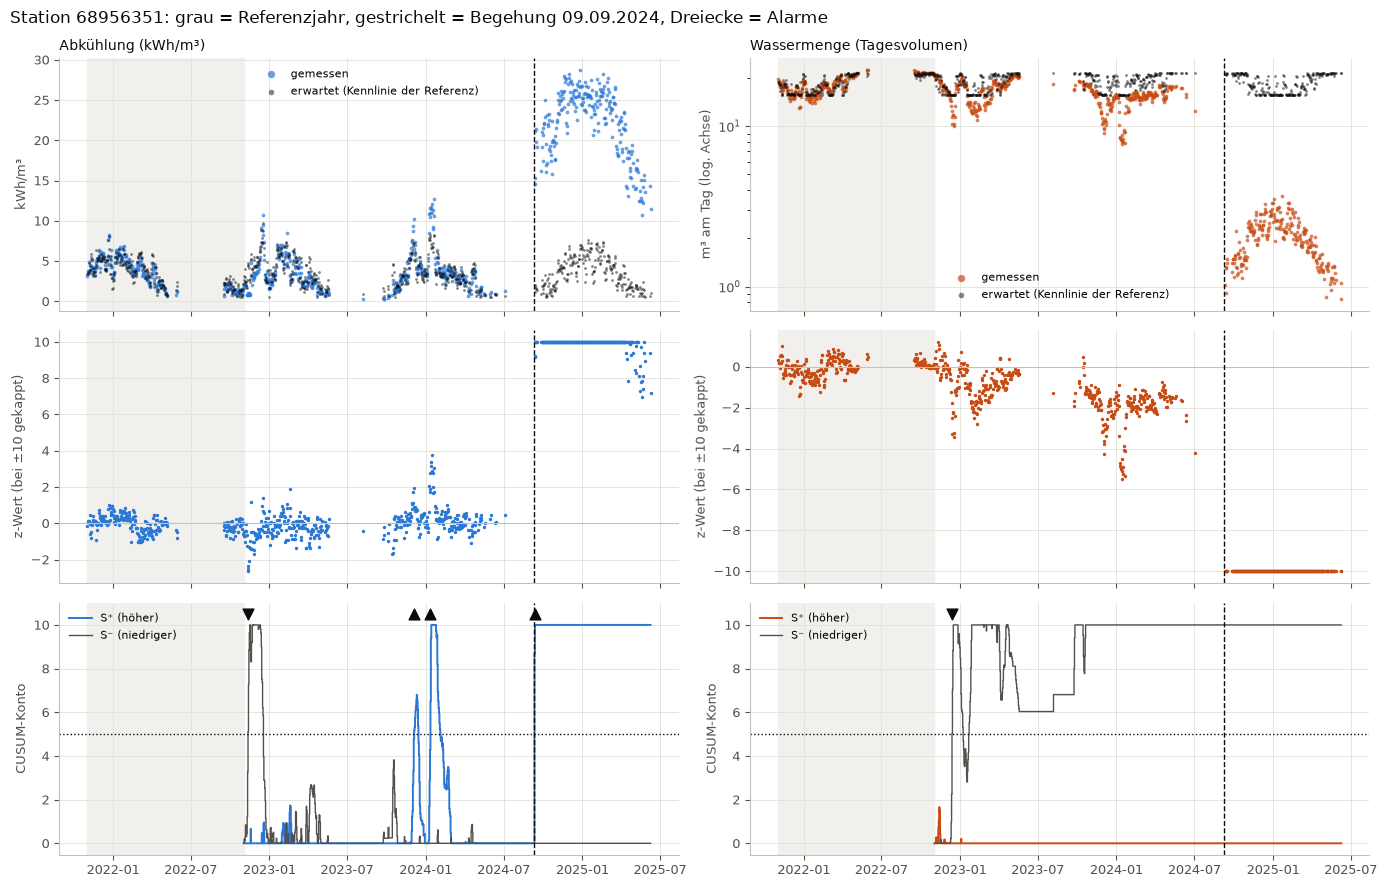

5 Alarme an dieser Station, davon im Fenster [-7, +60] Tage um die Begehung:


,zaehler,kanal,datum,richtung,beginn,heiztage_bis_alarm,tage_nach_begehung
3,68956351,kwh_pro_m3,2024-09-11,hoeher,2024-09-11,1,2


alle Alarme dieser Station:


,zaehler,kanal,datum,richtung,beginn,heiztage_bis_alarm,tage_nach_begehung
0,68956351,kwh_pro_m3,2022-11-12,niedriger,2022-11-03,10,-667
1,68956351,kwh_pro_m3,2023-12-05,hoeher,2023-11-29,7,-279
2,68956351,kwh_pro_m3,2024-01-12,hoeher,2024-01-08,5,-241
3,68956351,kwh_pro_m3,2024-09-11,hoeher,2024-09-11,1,2
4,68956351,log_volumen,2022-12-13,niedriger,2022-12-09,5,-636


In [11]:
if BEISPIEL not in stationen:
    grund = referenz.at[BEISPIEL, "status"] if BEISPIEL in referenz.index else "keine verwendbaren Heiztage"
    print(f"{BEISPIEL} wird nicht ueberwacht: {grund}")
else:
    v_bsp, al_bsp = verlauf_station(BEISPIEL)
    al_bsp = pd.DataFrame(al_bsp)
    fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharex=True)
    for nr, (kanal, titel) in enumerate(KANAELE.items()):
        v = v_bsp[v_bsp["kanal"] == kanal]
        farbe = FARBE_KANAL[kanal]
        ax = axes[0, nr]
        ax.scatter(v["datum"], anzeige(kanal, v["gemessen"]), s=7, color=farbe, alpha=0.7,
                   linewidths=0, label="gemessen")
        ax.scatter(v["datum"], anzeige(kanal, v["erwartet"]), s=4, color=TINTE, alpha=0.5,
                   linewidths=0, label="erwartet (Kennlinie der Referenz)")
        if kanal == "log_volumen":
            ax.set_yscale("log")
        ax.set_ylabel("m³ am Tag (log. Achse)" if kanal == "log_volumen" else "kWh/m³",
                      fontsize=9, color=TINTE_LEISE)
        ax.set_title(titel, loc="left", fontsize=10, color=TINTE)
        ax.legend(frameon=False, fontsize=8, markerscale=2)
        ax = axes[1, nr]
        ax.scatter(v["datum"], v["z"].clip(-10, 10), s=6, color=farbe, linewidths=0)
        ax.axhline(0, color=ACHSE, linewidth=0.8)
        ax.set_ylabel("z-Wert (bei ±10 gekappt)", fontsize=9, color=TINTE_LEISE)
        ax = axes[2, nr]
        u = v[~v["referenz"]]
        ax.plot(u["datum"], u["s_plus"], color=farbe, linewidth=1.4, drawstyle="steps-post", label="S⁺ (höher)")
        ax.plot(u["datum"], u["s_minus"], color=TINTE_LEISE, linewidth=1.0, drawstyle="steps-post",
                label="S⁻ (niedriger)")
        ax.axhline(CUSUM_H, color=TINTE, linestyle=":", linewidth=1)
        if len(al_bsp):
            for a in al_bsp[al_bsp["kanal"] == kanal].itertuples():
                y = CUSUM_MAX * 1.05
                ax.scatter(a.datum, y, marker="^" if a.richtung > 0 else "v", s=60, color=TINTE, zorder=3)
        ax.set_ylabel("CUSUM-Konto", fontsize=9, color=TINTE_LEISE)
        ax.legend(frameon=False, fontsize=8, loc="upper left")
        for ax in axes[:, nr]:
            ax.axvspan(referenz.at[BEISPIEL, "ref_start"], referenz.at[BEISPIEL, "ref_ende"],
                       color=FLAECHE, zorder=0)
            ax.axvline(BEISPIEL_DATUM, color=TINTE, linestyle="--", linewidth=1)
            stil(ax)
    fig.suptitle(f"Station {BEISPIEL}: grau = Referenzjahr, gestrichelt = Begehung "
                 f"{BEISPIEL_DATUM:%d.%m.%Y}, Dreiecke = Alarme", x=0.01, ha="left", color=TINTE)
    fig.tight_layout()
    plt.show()

    if len(al_bsp):
        al_bsp["richtung"] = al_bsp["richtung"].map({1: "hoeher", -1: "niedriger"})
        al_bsp["tage_nach_begehung"] = (al_bsp["datum"] - BEISPIEL_DATUM).dt.days
        print(f"{len(al_bsp)} Alarme an dieser Station, davon im Fenster "
              f"[-{FENSTER_VOR}, +{FENSTER_NACH}] Tage um die Begehung:")
        nah = al_bsp[al_bsp["tage_nach_begehung"].between(-FENSTER_VOR, FENSTER_NACH)]
        display(nah if len(nah) else "keiner")
        print("alle Alarme dieser Station:")
        display(al_bsp)
    else:
        print("keine Alarme an dieser Station")

**Wie man das Bild liest** (links Abkühlung, rechts Wassermenge)
- oben: farbig = gemessen, schwarz = Erwartung aus der Referenz. Grau hinterlegt ist das Referenzjahr.
- Mitte: z-Wert, bei ±10 gekappt.
- unten: die beiden CUSUM-Konten, gepunktet die Schwelle h. Dreiecke markieren Alarme (▲ höher, ▼ niedriger).

**Ergebnis**
- Abkühlung: Alarm "höher" am 11.09.2024, 2 Tage nach der Begehung, schon am ersten Heiztag des Laufs. Das ist der erwartete Befund.
- Wassermenge: kein Alarm im Fenster um die Begehung. Der einzige Wassermengen-Alarm liegt im Dezember 2022 (niedriger).
- Vor der Reparatur ist die Station nicht ruhig: 4 von 5 Alarmen liegen davor (Abkühlung niedriger 11/2022, höher 12/2023 und 01/2024; Wassermenge niedriger 12/2022).
- Der Ventilfall wird also gefunden, aber nur in einem Kanal, und die Station hatte vorher schon Alarme.

## 9 Lauf über alle Stationen

- Dieselben Parameter für alle Stationen, nichts wird je Station nachjustiert.
- Zwei Fragen: Wie viele Alarme gibt es? Häufen sie sich zu bestimmten Zeiten?
- Die zweite Frage ist eine Selbstkontrolle: Alarme jeden Oktober überall deuten auf etwas, das das Modell nicht kennt (z. B. Netzvorlauftemperatur, Anlaufen nach dem Sommer).

89 Stationen ueberwacht, zusammen 133 Stationsjahre


479 Alarme in beiden Kanaelen = 3.6 je Station und Jahr (NB 14: knapp 5)


,Kanal,Richtung,Alarme,je Stationsjahr,Stationen mit Alarm,Heiztage bis Alarm (Median)
0,Abkühlung (kWh/m³),niedriger,150,1.13,70,10.0
1,Abkühlung (kWh/m³),höher,90,0.68,40,8.0
2,Wassermenge (Tagesvolumen),niedriger,142,1.07,64,6.5
3,Wassermenge (Tagesvolumen),höher,97,0.73,53,10.0


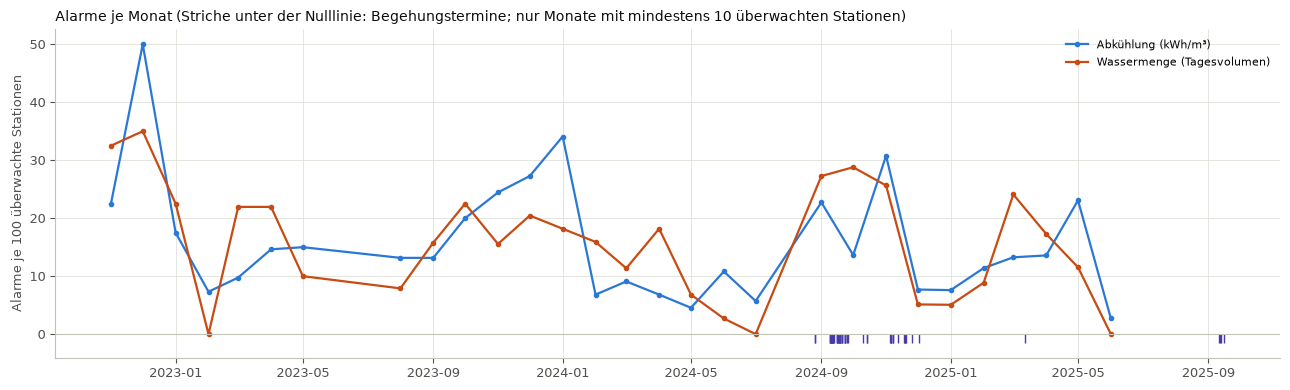

In [12]:
verlaeufe, alarm_zeilen = [], []
for zaehler in stationen:
    v, al = verlauf_station(zaehler)
    verlaeufe.append(v)
    alarm_zeilen.extend(al)
verlauf = pd.concat(verlaeufe, ignore_index=True)
alarme = pd.DataFrame(alarm_zeilen, columns=["zaehler", "kanal", "datum", "richtung", "beginn",
                                             "heiztage_bis_alarm"])

ueberwacht = verlauf[~verlauf["referenz"]]
jahre_je_station = ueberwacht.groupby("zaehler")["datum"].agg(lambda s: (s.max() - s.min()).days / 365.25)
stationsjahre = jahre_je_station.sum()
print(f"{len(stationen)} Stationen ueberwacht, zusammen {stationsjahre:.0f} Stationsjahre")
print(f"{len(alarme)} Alarme in beiden Kanaelen = {len(alarme) / stationsjahre:.1f} je Station und Jahr "
      f"(NB 14: knapp 5)")

zeilen = []
for (kanal, richtung), g in alarme.groupby(["kanal", "richtung"]):
    zeilen.append({"Kanal": KANAELE[kanal], "Richtung": "höher" if richtung > 0 else "niedriger",
                   "Alarme": len(g), "je Stationsjahr": len(g) / stationsjahre,
                   "Stationen mit Alarm": g["zaehler"].nunique(),
                   "Heiztage bis Alarm (Median)": g["heiztage_bis_alarm"].median()})
display(pd.DataFrame(zeilen).round(2))

#Alarme je Monat, bezogen auf die überwachten Stationen
monat = ueberwacht[ueberwacht["kanal"] == "kwh_pro_m3"].assign(monat=lambda x: x["datum"].dt.to_period("M"))
aktiv = monat.groupby("monat")["zaehler"].nunique()
aktiv = aktiv[aktiv >= 10]
alarm_monat = (alarme.assign(monat=alarme["datum"].dt.to_period("M"))
               .groupby(["monat", "kanal"]).size().unstack(fill_value=0)
               .reindex(index=aktiv.index, columns=list(KANAELE), fill_value=0))

fig, ax = plt.subplots(figsize=(13, 4))
x = aktiv.index.to_timestamp()
for kanal, titel in KANAELE.items():
    ax.plot(x, 100 * alarm_monat[kanal] / aktiv, color=FARBE_KANAL[kanal], linewidth=1.6,
            marker="o", markersize=3, label=titel)
ax.vlines(faelle_alle["datum"], 0, -1.5, color=FARBE_BEGANGEN, linewidth=1)
ax.axhline(0, color=ACHSE, linewidth=0.8)
ax.set_ylabel("Alarme je 100 überwachte Stationen", fontsize=9, color=TINTE_LEISE)
ax.set_title("Alarme je Monat (Striche unter der Nulllinie: Begehungstermine; nur Monate mit mindestens "
             "10 überwachten Stationen)", loc="left", fontsize=10, color=TINTE)
ax.legend(frameon=False, fontsize=8)
stil(ax)
fig.tight_layout()
plt.show()

**Was die Zelle macht**
- rechnet `verlauf_station()` für alle überwachten Stationen; `verlauf` = eine Zeile je Station, Kanal und Heiztag, `alarme` = eine Zeile je Alarm
- Stationsjahre = Summe der überwachten Zeitspannen; darauf bezogen ist die Alarmrate unabhängig von der Datenlänge
- die Grafik teilt die Alarme eines Monats durch die Zahl der in dem Monat überwachten Stationen

**Wie man die Grafik liest**
- Spitzen im Herbst nach den Begehungen (violette Striche) passen zur Wirkung der Begehungen.
- Spitzen jeden Herbst, auch ohne Begehungen, deuten auf einen jahreszeitlichen Effekt, den das Modell nicht kennt.
- Spitzen in einem Monat bei allen Stationen deuten auf ein netzweites Ereignis.

**Ergebnis**
- 89 Stationen, zusammen 133 Stationsjahre, 479 Alarme in beiden Kanälen = 3,6 je Station und Jahr. Der Kennlinienmonitor (Notebook 13) kam auf knapp 5.
- Das ist deutlich mehr als die theoretische Rate aus Abschnitt 7 (etwa einer alle zwei bis drei Jahre je Kanal).
- Abkühlung: 150 Alarme niedriger (70 Stationen), 90 höher (40 Stationen). Wassermenge: 142 niedriger (64 Stationen), 97 höher (53 Stationen).
- Im Median 6,5 bis 10 Heiztage bis zum Alarm. Das Monatsmuster steht nur im Bild und ist hier nicht in Zahlen ausgewertet.

## 10 Sieht das Modell die Begehungen überhaupt?

- Vorfrage: Verschiebt sich das wetterbereinigte Niveau nach einer Begehung stärker als bei Stationen ohne Begehung? Ohne diese Verschiebung kann auch kein Alarm sie finden.
- Verfahren: Differenz-von-Differenzen (DiD) aus Notebook 02, aber auf Residuen.
  - Δ begangen = Median der Residuen der ersten 30 Heiztage nach minus der letzten 30 vor der Begehung (je 7 Tage Abstand, höchstens ein Jahr weit)
  - Δ Kontrolle = dasselbe für Stationen ohne eigene Begehung im Zeitraum, davon der Median; DiD = Δ begangen − Δ Kontrolle
- Vorteil: Das Modell rechnet den Temperaturunterschied zwischen Frühjahr und Herbst heraus, die Kontrollgruppe den Rest. Notebook 02 hatte nur die Kontrollgruppe, Notebook 05 nur das Wetter.
- Einheiten: Abkühlung in kWh/m³ (positiv = besser), Wassermenge in Prozent (negativ = weniger Wasser).

In [13]:
verlauf_je = {key: g.sort_values("datum") for key, g in verlauf.groupby(["zaehler", "kanal"])}


def begehung_zwischen(zaehler, von, bis):
    """Hatte die Station zwischen von und bis eine Begehung?"""
    return any(von <= t <= bis for t in termine.get(zaehler, []))


def vorher_nachher(zaehler, kanal, datum):
    """Median-Residuum der ersten Heiztage nach minus der letzten vor dem Datum.

    Rueckgabe (Differenz, erster verwendeter Tag, letzter verwendeter Tag) oder None,
    wenn eine Seite zu wenige Tage hat.
    """
    v = verlauf_je[(zaehler, kanal)]
    abstand = pd.Timedelta(days=WIRKUNG_ABSTAND)
    weit = pd.Timedelta(days=WIRKUNG_MAX_TAGE)
    vor = v[(v["datum"] < datum - abstand) & (v["datum"] >= datum - weit)].tail(WIRKUNG_TAGE)
    nach = v[(v["datum"] > datum + abstand) & (v["datum"] <= datum + weit)].head(WIRKUNG_TAGE)
    if len(vor) < MIN_WIRKUNG_TAGE or len(nach) < MIN_WIRKUNG_TAGE:
        return None
    return nach["residuum"].median() - vor["residuum"].median(), vor["datum"].min(), nach["datum"].max()


#Fälle: überwachte Stationen, Termin nach Ende der Referenz
faelle = faelle_alle[faelle_alle["zaehler"].isin(stationen)].copy()
faelle = faelle[faelle["datum"] >= faelle["zaehler"].map(referenz["ref_ende"])].reset_index(drop=True)
print(f"{len(faelle)} Termine an {faelle['zaehler'].nunique()} ueberwachten Stationen")

kontroll_cache = {}


def kontroll_deltas(kanal, datum):
    """Differenz je Station ohne Begehung im verwendeten Zeitraum (einmal je Datum gerechnet)."""
    if (kanal, datum) not in kontroll_cache:
        werte = {}
        for z in stationen:
            r = vorher_nachher(z, kanal, datum)
            if r is None:
                continue
            delta, von, bis = r
            if begehung_zwischen(z, von - pd.Timedelta(days=WIRKUNG_ABSTAND), bis + pd.Timedelta(days=WIRKUNG_ABSTAND)):
                continue
            werte[z] = delta
        kontroll_cache[(kanal, datum)] = werte
    return kontroll_cache[(kanal, datum)]


zeilen = []
for fall in faelle.itertuples(index=False):
    for kanal in KANAELE:
        eigen = vorher_nachher(fall.zaehler, kanal, fall.datum)
        if eigen is None:
            continue
        kontrolle = [d for z, d in kontroll_deltas(kanal, fall.datum).items() if z != fall.zaehler]
        if len(kontrolle) < MIN_KONTROLLEN:
            continue
        zeilen.append({"zaehler": fall.zaehler, "datum": fall.datum, "kategorie": fall.kategorie,
                       "mechanisch": fall.mechanisch, "kanal": kanal, "delta": eigen[0],
                       "delta_kontrolle": float(np.median(kontrolle)), "n_kontrolle": len(kontrolle)})
wirkung = pd.DataFrame(zeilen, columns=["zaehler", "datum", "kategorie", "mechanisch", "kanal", "delta",
                                        "delta_kontrolle", "n_kontrolle"])
wirkung["did"] = wirkung["delta"] - wirkung["delta_kontrolle"]


def in_einheit(kanal, x):
    return prozent(x) if kanal == "log_volumen" else x


ERWARTET = {"kwh_pro_m3": +1, "log_volumen": -1}   #Richtung einer Verbesserung
zeilen = []
for kanal, g in wirkung.groupby("kanal"):
    p = stats.wilcoxon(g["did"]).pvalue if len(g) >= 6 else np.nan
    zeilen.append({"Kanal": KANAELE[kanal], "Faelle": len(g),
                   "Median Δ begangen": in_einheit(kanal, g["delta"].median()),
                   "Median Δ Kontrolle": in_einheit(kanal, g["delta_kontrolle"].median()),
                   "Median DiD": in_einheit(kanal, g["did"].median()),
                   "Anteil in Richtung Verbesserung": (np.sign(g["did"]) == ERWARTET[kanal]).mean(),
                   "Wilcoxon p (zweiseitig)": p,
                   "Kontrollstationen je Fall (Median)": g["n_kontrolle"].median()})
print("Einheiten: Abkuehlung in kWh/m³, Wassermenge in Prozent")
display(pd.DataFrame(zeilen).round(3))

REIHENFOLGE = {"keine": 0, "geringe": 1, "mittlere": 2, "viele": 3}
for gruppe in ("mechanisch", "kategorie"):
    zeilen = []
    for (kanal, wert), g in wirkung.groupby(["kanal", gruppe]):
        zeilen.append({"Kanal": KANAELE[kanal], gruppe: wert, "Faelle": len(g),
                       "Median DiD": in_einheit(kanal, g["did"].median()),
                       "Anteil in Richtung Verbesserung": (np.sign(g["did"]) == ERWARTET[kanal]).mean()})
    tab = pd.DataFrame(zeilen)
    if gruppe == "kategorie" and len(tab):
        tab["_ordnung"] = tab["kategorie"].map(REIHENFOLGE).fillna(9)
        tab = tab.sort_values(["Kanal", "_ordnung"]).drop(columns="_ordnung")
    print(f"nach {gruppe}:")
    display(tab.round(2))

50 Termine an 48 ueberwachten Stationen


Einheiten: Abkuehlung in kWh/m³, Wassermenge in Prozent


,Kanal,Faelle,Median Δ begangen,Median Δ Kontrolle,Median DiD,Anteil in Richtung Verbesserung,Wilcoxon p (zweiseitig),Kontrollstationen je Fall (Median)
0,Abkühlung (kWh/m³),43,0.793,-0.637,1.112,0.558,0.196,48.0
1,Wassermenge (Tagesvolumen),43,0.531,14.591,-11.236,0.651,0.026,48.0


nach mechanisch:


,Kanal,mechanisch,Faelle,Median DiD,Anteil in Richtung Verbesserung
0,Abkühlung (kWh/m³),False,28,-0.46,0.46
1,Abkühlung (kWh/m³),True,15,1.86,0.73
2,Wassermenge (Tagesvolumen),False,28,-6.93,0.57
3,Wassermenge (Tagesvolumen),True,15,-13.79,0.80


nach kategorie:


,Kanal,kategorie,Faelle,Median DiD,Anteil in Richtung Verbesserung
1,Abkühlung (kWh/m³),keine,2,-2.57,0.00
0,Abkühlung (kWh/m³),geringe,4,-0.25,0.50
2,Abkühlung (kWh/m³),mittlere,25,1.18,0.60
3,Abkühlung (kWh/m³),viele,12,1.40,0.58
5,Wassermenge (Tagesvolumen),keine,2,12.07,0.50
4,Wassermenge (Tagesvolumen),geringe,4,7.35,0.25
6,Wassermenge (Tagesvolumen),mittlere,25,-11.34,0.68
7,Wassermenge (Tagesvolumen),viele,12,-9.49,0.75


**Was die Zelle macht**
- `vorher_nachher()` rechnet die Verschiebung des Medianresiduums um ein Datum
- `faelle` = Begehungstermine an überwachten Stationen nach dem Ende ihrer Referenz; für jeden Fall dieselbe Rechnung an allen Kontrollstationen
- Tabellen: je Kanal, dann nach mechanischem Befund und nach Kategorie der Begehungstabelle

**Wie man das Ergebnis liest**
- Median DiD = typische wetterbereinigte Wirkung über das hinaus, was ohnehin passiert. Zum Vergleich ohne Kontrollgruppe: Notebook 05 +1,2 bis +1,3 kWh/m³, Notebook 11 auf Tagesebene +0,6 kWh/m³ (nicht gesichert).
- Anteil in Richtung Verbesserung: 0,5 wäre Zufall.
- Wilcoxon p: Ist der Median der DiD von null verschieden? Fälle derselben Station sind nicht unabhängig, p ist eher zu optimistisch.

**Ergebnis**
- 50 Termine an 48 überwachten Stationen, je Kanal 43 auswertbare Fälle, im Median 48 Kontrollstationen je Fall.
- Abkühlung: DiD im Median +1,11 kWh/m³, 56 % der Fälle in Richtung Verbesserung, p = 0,20. Hinweis auf eine Wirkung, aber nicht signifikant.
- Wassermenge: DiD im Median −11,2 %, 65 % in Richtung Verbesserung, p = 0,026. Die Kontrollstationen ziehen nachher im Median 14,6 % mehr Wasser, die begangenen kaum mehr (+0,5 %).
- Mechanischer Befund (15 Fälle): Abkühlung +1,86 kWh/m³ (73 % besser), Wassermenge −13,8 % (80 % besser). Ohne mechanischen Befund (28 Fälle): −0,46 kWh/m³ (46 %) und −6,9 % (57 %). Das ist konsistent mit Notebook 14, jetzt mit Wetterbereinigung und Kontrollgruppe.
- Kategorie: "mittlere" (25) und "viele" (12) zeigen in beiden Kanälen in Richtung Verbesserung; "keine" (2) und "geringe" (4) sind zu wenige Fälle für eine Aussage.

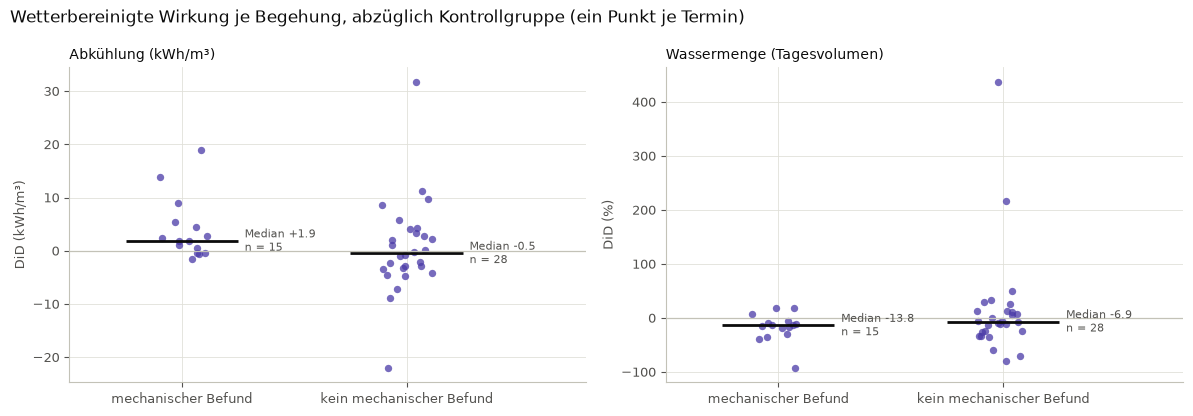

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
rng = np.random.default_rng(SEED)
for ax, (kanal, titel) in zip(axes, KANAELE.items()):
    g = wirkung[wirkung["kanal"] == kanal]
    for pos, (wert, name) in enumerate([(True, "mechanischer Befund"), (False, "kein mechanischer Befund")]):
        y = in_einheit(kanal, g.loc[g["mechanisch"] == wert, "did"].to_numpy())
        x = pos + rng.uniform(-0.12, 0.12, len(y))
        ax.scatter(x, y, s=28, color=FARBE_BEGANGEN, alpha=0.75, linewidths=0)
        if len(y):
            ax.hlines(np.median(y), pos - 0.25, pos + 0.25, color=TINTE, linewidth=2)
            ax.text(pos + 0.28, np.median(y), f"Median {np.median(y):+.1f}\nn = {len(y)}",
                    fontsize=8, color=TINTE_LEISE, va="center")
    ax.axhline(0, color=ACHSE, linewidth=0.9)
    ax.set_xticks([0, 1], ["mechanischer Befund", "kein mechanischer Befund"])
    ax.set_xlim(-0.5, 1.8)
    einheit = "%" if kanal == "log_volumen" else "kWh/m³"
    ax.set_ylabel(f"DiD ({einheit})", fontsize=9, color=TINTE_LEISE)
    ax.set_title(titel, loc="left", fontsize=10, color=TINTE)
    stil(ax)
fig.suptitle("Wetterbereinigte Wirkung je Begehung, abzüglich Kontrollgruppe (ein Punkt je Termin)",
             x=0.01, ha="left", color=TINTE)
fig.tight_layout()
plt.show()

**Wie man das Bild liest**
- Jeder Punkt ist ein Begehungstermin, der Querstrich der Median der Gruppe.
- Abkühlung: über null = Station kühlt nach der Begehung besser aus als die Kontrollgruppe. Wassermenge: unter null = weniger Wasser.
- Weit entfernte Einzelpunkte sind die interessanten Fälle für die ÜZ.

**Ergebnis**
- Die Mediane entsprechen der Tabelle oben: mechanisch +1,9 kWh/m³ und −13,8 %, nicht mechanisch −0,5 kWh/m³ und −6,9 %.
- Die Streuung der Einzelpunkte steht nur im Bild; bei 15 gegen 28 Fällen ist der Unterschied der Gruppen nicht getestet.

## 11 Treffen die Alarme die Begehungen?

- Treffer: mindestens ein Alarm im Fenster 7 Tage vor bis 60 Tage nach der Begehung, je Kanal und für "einer der beiden".
- Erwartung ohne Begehung: Anteil der Kontrollstationen mit Alarm im selben Fenster. Kontrollstation = überwachte Station mit mindestens 5 Heiztagen im Fenster, ohne eigene Begehung im Fenster und in den 60 Tagen davor.
- Test: Binomialtest, einseitig.
- Kontrollgruppe statt Zufallsbasis wie in Notebook 13, weil die Begehungen fast alle im September lagen. Ein allgemeiner Herbsteffekt trifft die Kontrollgruppe genauso.

In [15]:
alarme_je = {key: g["datum"] for key, g in alarme.groupby(["zaehler", "kanal"])}
tage_je = {z: g["datum"] for z, g in ueberwacht[ueberwacht["kanal"] == "kwh_pro_m3"].groupby("zaehler")}
PRUEFUNGEN = {"Abkühlung": ["kwh_pro_m3"], "Wassermenge": ["log_volumen"],
              "einer der beiden": list(KANAELE)}


def alarm_im_fenster(zaehler, kanaele, von, bis):
    for kanal in kanaele:
        s = alarme_je.get((zaehler, kanal))
        if s is not None and ((s >= von) & (s <= bis)).any():
            return True
    return False


def beobachtbar(zaehler, von, bis):
    """Hat die Station im Fenster genug ueberwachte Heiztage, um ueberhaupt alarmieren zu koennen?"""
    s = tage_je.get(zaehler)
    return s is not None and int(((s >= von) & (s <= bis)).sum()) >= MIN_TAGE_IM_FENSTER


zeilen = []
for fall in faelle.itertuples(index=False):
    von = fall.datum - pd.Timedelta(days=FENSTER_VOR)
    bis = fall.datum + pd.Timedelta(days=FENSTER_NACH)
    if not beobachtbar(fall.zaehler, von, bis):
        continue
    kontrollen = [z for z in stationen
                  if z != fall.zaehler and beobachtbar(z, von, bis)
                  and not begehung_zwischen(z, von - pd.Timedelta(days=KONTROLL_VORLAUF), bis)]
    if len(kontrollen) < MIN_KONTROLLEN:
        continue
    for name, kanaele in PRUEFUNGEN.items():
        zeilen.append({"zaehler": fall.zaehler, "datum": fall.datum, "mechanisch": fall.mechanisch,
                       "kategorie": fall.kategorie, "pruefung": name,
                       "treffer": alarm_im_fenster(fall.zaehler, kanaele, von, bis),
                       "kontrollquote": np.mean([alarm_im_fenster(z, kanaele, von, bis) for z in kontrollen]),
                       "n_kontrolle": len(kontrollen)})
treffer = pd.DataFrame(zeilen, columns=["zaehler", "datum", "mechanisch", "kategorie", "pruefung",
                                        "treffer", "kontrollquote", "n_kontrolle"])


def bilanz(t, gruppen):
    """Treffer gegen Kontrollquote je Gruppe, mit einseitigem Binomialtest."""
    zeilen = []
    for schluessel, g in t.groupby(gruppen, sort=False):
        n, k = len(g), int(g["treffer"].sum())
        p0 = float(g["kontrollquote"].mean())
        p = stats.binomtest(k, n, p0, alternative="greater").pvalue if 0 < p0 < 1 else np.nan
        schluessel = schluessel if isinstance(schluessel, tuple) else (schluessel,)
        zeilen.append({**dict(zip(gruppen, schluessel)), "Faelle": n, "Treffer": k, "Quote": k / n,
                       "Kontrollquote": p0, "Hebel": (k / n) / p0 if p0 > 0 else np.nan,
                       "p (einseitig)": p})
    return pd.DataFrame(zeilen)


gesamt = bilanz(treffer, ["pruefung"])
nach_art = bilanz(treffer, ["pruefung", "mechanisch"])
display(gesamt.round(3))
display(nach_art.round(3))

#Verzögerung und Richtung des ersten Alarms nach der Begehung
erste = []
for fall in faelle.itertuples(index=False):
    for kanal in KANAELE:
        s = alarme[(alarme["zaehler"] == fall.zaehler) & (alarme["kanal"] == kanal)
                   & alarme["datum"].between(fall.datum - pd.Timedelta(days=FENSTER_VOR),
                                             fall.datum + pd.Timedelta(days=FENSTER_NACH))]
        if len(s):
            a = s.sort_values("datum").iloc[0]
            erste.append({"kanal": kanal, "tage": (a["datum"] - fall.datum).days,
                          "verbesserung": a["richtung"] == ERWARTET[kanal]})
erste = pd.DataFrame(erste, columns=["kanal", "tage", "verbesserung"])
for kanal, g in erste.groupby("kanal"):
    print(f"{KANAELE[kanal]}: erster Alarm im Median {g['tage'].median():.0f} Tage nach der Begehung, "
          f"{g['verbesserung'].mean():.0%} davon in Richtung Verbesserung (n = {len(g)})")

,pruefung,Faelle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig)
0,Abkühlung,43,22,0.512,0.290,1.767,0.002
1,Wassermenge,43,23,0.535,0.359,1.490,0.014
2,einer der beiden,43,30,0.698,0.526,1.326,0.017


,pruefung,mechanisch,Faelle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig)
0,Abkühlung,True,14,5,0.357,0.279,1.278,0.349
1,Wassermenge,True,14,9,0.643,0.376,1.709,0.039
2,einer der beiden,True,14,10,0.714,0.530,1.347,0.133
3,Abkühlung,False,29,17,0.586,0.295,1.990,0.001
4,Wassermenge,False,29,14,0.483,0.351,1.376,0.099
5,einer der beiden,False,29,20,0.690,0.524,1.316,0.054


Abkühlung (kWh/m³): erster Alarm im Median 22 Tage nach der Begehung, 41% davon in Richtung Verbesserung (n = 22)
Wassermenge (Tagesvolumen): erster Alarm im Median 11 Tage nach der Begehung, 83% davon in Richtung Verbesserung (n = 23)


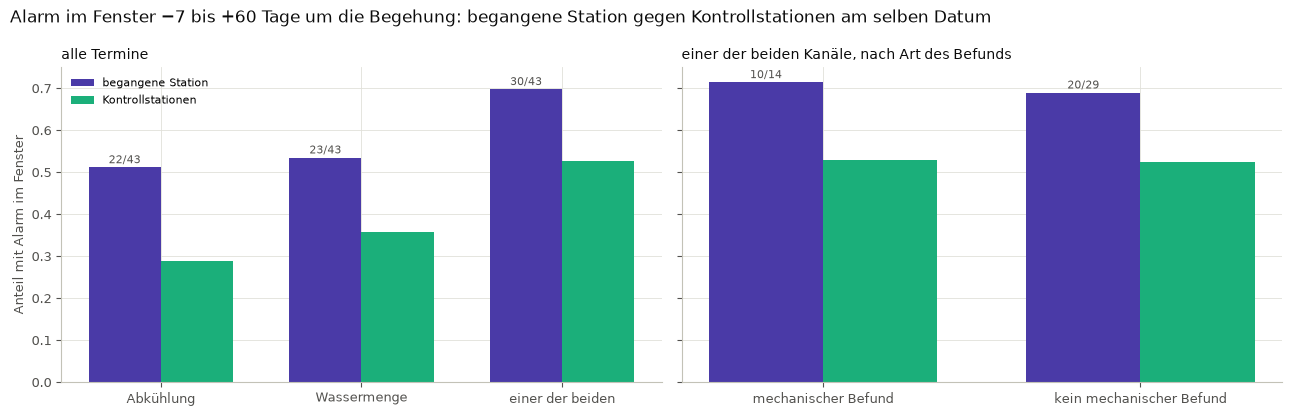

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
breite = 0.36
for ax, (daten, titel) in zip(axes, [(gesamt, "alle Termine"),
                                     (nach_art[nach_art["pruefung"] == "einer der beiden"],
                                      "einer der beiden Kanäle, nach Art des Befunds")]):
    if "mechanisch" in daten.columns:
        namen = ["mechanischer Befund" if m else "kein mechanischer Befund" for m in daten["mechanisch"]]
    else:
        namen = list(daten["pruefung"])
    x = np.arange(len(daten))
    ax.bar(x - breite / 2, daten["Quote"], breite, color=FARBE_BEGANGEN, label="begangene Station")
    ax.bar(x + breite / 2, daten["Kontrollquote"], breite, color=FARBE_KONTROLLE, label="Kontrollstationen")
    for xi, (k, n) in enumerate(zip(daten["Treffer"], daten["Faelle"])):
        ax.text(xi - breite / 2, daten["Quote"].iloc[xi] + 0.01, f"{k}/{n}", ha="center", fontsize=8,
                color=TINTE_LEISE)
    ax.set_xticks(x, namen, fontsize=9)
    ax.set_title(titel, loc="left", fontsize=10, color=TINTE)
    stil(ax)
axes[0].set_ylabel("Anteil mit Alarm im Fenster", fontsize=9, color=TINTE_LEISE)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(f"Alarm im Fenster −{FENSTER_VOR} bis +{FENSTER_NACH} Tage um die Begehung: "
             "begangene Station gegen Kontrollstationen am selben Datum", x=0.01, ha="left", color=TINTE)
fig.tight_layout()
plt.show()

**Was die beiden Zellen machen**
- prüfen je Termin, ob die begangene Station im Fenster alarmiert, und welcher Anteil der Kontrollstationen
- `gesamt`: je Prüfung; `nach_art`: zusätzlich nach mechanischem Befund
- darunter: Tage bis zum ersten Alarm und ob er in Richtung Verbesserung zeigt
- Grafik: Quote (violett) gegen Kontrollquote (türkis), über den Balken Treffer/Fälle

**Wie man das Ergebnis liest**
- Hebel = Quote / Kontrollquote. 1 heißt: nach einer Begehung genauso oft Alarm wie ohne. Notebook 13 kam auf rund 1,3, Notebook 14 bei mechanischen Befunden auf rund 1,8 (0,526 gegen 0,296).
- p unter 0,05 gilt üblicherweise als nicht mehr zufällig. Die Fälle sind nicht ganz unabhängig, p ist eher zu optimistisch.
- Richtung: "Abkühlung höher" oder "Wassermenge niedriger" passt zu einer Verbesserung.

**Ergebnis**
- Abkühlung: 22 von 43 Terminen mit Alarm (0,51) gegen 0,29 bei der Kontrollgruppe, Hebel 1,77, p = 0,002.
- Wassermenge: 23 von 43 (0,53) gegen 0,36, Hebel 1,49, p = 0,014.
- Einer der beiden Kanäle: 30 von 43 (0,70) gegen 0,53, Hebel 1,33, p = 0,017. Etwa so stark wie der Kennlinienmonitor (1,3).
- Richtung: Wassermenge-Alarme im Median 11 Tage nach der Begehung, 83 % in Richtung Verbesserung. Abkühlungs-Alarme im Median 22 Tage danach, aber nur 41 % in Richtung Verbesserung.
- Nach Art: Bei mechanischen Befunden (14 Fälle) trifft nur die Wassermenge knapp (9 von 14, Hebel 1,71, p = 0,039), die Abkühlung nicht (5 von 14, p = 0,35). Ohne mechanischen Befund (29 Fälle) trifft die Abkühlung 17 von 29, Hebel 1,99, p = 0,001.
- Das widerspricht teilweise Abschnitt 10: Dort war die Wirkung bei mechanischen Befunden größer. Die Abkühlungs-Treffer zeigen zudem mehrheitlich nicht in Richtung Verbesserung.

## 12 Station gegen Flotte

- Lücke des Modells: Eine Station, die schon im ersten Jahr schlecht lief, gilt als normal und alarmiert nie.
- Ergänzung: die Abkühlung jeder Station bei einer Normtemperatur von 5 °C aus ihrer Kennlinie. So sind Stationen vergleichbar, auch wenn ihre Daten aus verschiedenen Wintern stammen (gleiche Idee wie der Bezugspunkt in Notebook 05).
  - Normkennzahl Referenz = Kennlinie bei 5 °C (erstes Jahr); Normkennzahl aktuell = Referenz + Median der Residuen der letzten 60 Heiztage
  - Abstand zur Flotte = (Flottenmedian − Station) / 1,15, in Kelvin Spreizung
- Nur die Abkühlung, weil kWh/m³ nicht von der Hausgröße abhängt.

Flottenmedian aktuell: 26.1 kWh/m³ bei 5 °C (= 22.7 K Spreizung)


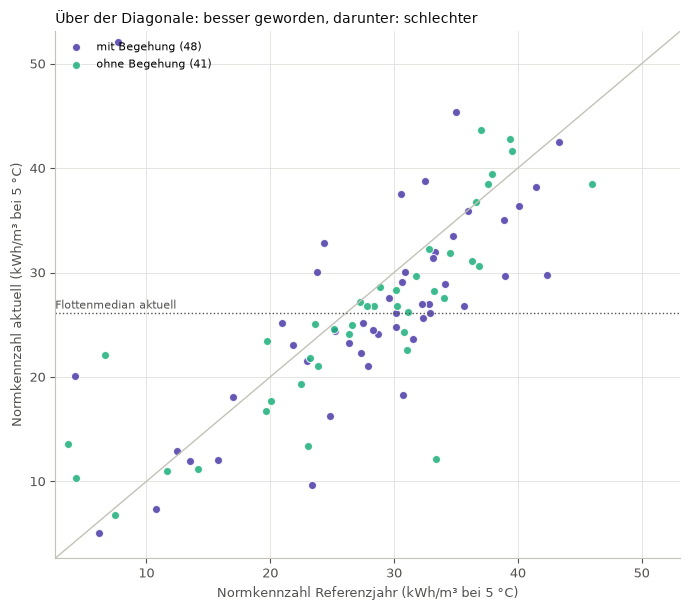

Zehn Stationen mit der niedrigsten Abkuehlung aktuell (groesstes Optimierungspotenzial):


,zaehler,norm_referenz,norm_aktuell,abstand_k,veraenderung,stand,begangen,alarme
72,80912182,6.21,5.04,18.35,-1.16,2025-06-09,True,3
50,72167793,7.43,6.73,16.88,-0.70,2025-06-09,False,2
34,72135442,10.75,7.37,16.32,-3.38,2025-06-09,True,8
65,80912173,23.39,9.66,14.33,-13.73,2025-06-09,True,3
40,72135480,4.32,10.30,13.78,5.98,2025-06-09,False,9
36,72135453,11.62,11.03,13.14,-0.60,2025-06-09,False,10
88,81062289,14.19,11.21,12.98,-2.97,2025-06-09,False,3
17,68956356,13.50,11.97,12.32,-1.53,2025-06-09,True,6
14,68956352,15.77,12.01,12.29,-3.76,2025-06-09,True,9
19,68956360,33.43,12.14,12.18,-21.29,2025-06-09,False,2


In [17]:
zeilen = []
for zaehler in stationen:
    norm_referenz = float(erwartung(zaehler, "kwh_pro_m3", T_NORM))
    letzte = verlauf_je[(zaehler, "kwh_pro_m3")].tail(AKTUELL_TAGE)
    zeilen.append({"zaehler": zaehler, "norm_referenz": norm_referenz,
                   "norm_aktuell": norm_referenz + letzte["residuum"].median(),
                   "stand": letzte["datum"].max(),
                   "alarme": int((alarme["zaehler"] == zaehler).sum()),
                   "begangen": zaehler in termine})
flotte = pd.DataFrame(zeilen)
median_flotte = flotte["norm_aktuell"].median()
flotte["abstand_k"] = (median_flotte - flotte["norm_aktuell"]) / RHO_C
flotte["veraenderung"] = flotte["norm_aktuell"] - flotte["norm_referenz"]
print(f"Flottenmedian aktuell: {median_flotte:.1f} kWh/m³ bei {T_NORM:g} °C "
      f"(= {median_flotte / RHO_C:.1f} K Spreizung)")

fig, ax = plt.subplots(figsize=(7, 6.2))
for wert, farbe, name in [(True, FARBE_BEGANGEN, "mit Begehung"), (False, FARBE_KONTROLLE, "ohne Begehung")]:
    g = flotte[flotte["begangen"] == wert]
    ax.scatter(g["norm_referenz"], g["norm_aktuell"], s=34, color=farbe, alpha=0.85, linewidths=0.8,
               edgecolors="white", label=f"{name} ({len(g)})")
grenzen = [flotte[["norm_referenz", "norm_aktuell"]].min().min() - 1,
           flotte[["norm_referenz", "norm_aktuell"]].max().max() + 1]
ax.plot(grenzen, grenzen, color=ACHSE, linewidth=1)
ax.axhline(median_flotte, color=TINTE_LEISE, linestyle=":", linewidth=1)
ax.text(grenzen[0], median_flotte + 0.4, "Flottenmedian aktuell", fontsize=8, color=TINTE_LEISE)
ax.set_xlim(grenzen)
ax.set_ylim(grenzen)
ax.set_xlabel(f"Normkennzahl Referenzjahr (kWh/m³ bei {T_NORM:g} °C)", fontsize=9, color=TINTE_LEISE)
ax.set_ylabel(f"Normkennzahl aktuell (kWh/m³ bei {T_NORM:g} °C)", fontsize=9, color=TINTE_LEISE)
ax.set_title("Über der Diagonale: besser geworden, darunter: schlechter", loc="left", fontsize=10, color=TINTE)
ax.legend(frameon=False, fontsize=8, loc="upper left")
stil(ax)
fig.tight_layout()
plt.show()

print("Zehn Stationen mit der niedrigsten Abkuehlung aktuell (groesstes Optimierungspotenzial):")
zahlen = ["norm_referenz", "norm_aktuell", "abstand_k", "veraenderung"]
display(flotte.nsmallest(10, "norm_aktuell")[["zaehler", *zahlen, "stand", "begangen", "alarme"]]
        .round({sp: 2 for sp in zahlen}))

In [18]:
#Gegenprobe mit NB 10: Anteil Heiztage im schlechtesten Tagestyp (bei K = 4 Typ D)
heiz = tage[tage["heiztag"] & tage["cluster"].notna()]
if len(heiz):
    schlechtester = heiz.groupby("cluster")["kwh_pro_m3"].median().idxmin()
    anteil = heiz.groupby("zaehler")["cluster"].apply(lambda c: (c == schlechtester).mean())
    vergleich = flotte.set_index("zaehler").join(anteil.rename("anteil_schlechtester_typ"), how="inner")
    rho, p = stats.spearmanr(vergleich["norm_referenz"], vergleich["anteil_schlechtester_typ"])
    print(f"schlechtester Tagestyp in NB 06: {schlechtester}")
    print(f"Spearman Normkennzahl Referenz gegen Anteil dieses Typs: rho = {rho:+.2f}, p = {p:.2g}, "
          f"n = {len(vergleich)}")
else:
    print("hast_tage.csv enthaelt keine Clusterspalte - Gegenprobe uebersprungen")

schlechtester Tagestyp in NB 06: D
Spearman Normkennzahl Referenz gegen Anteil dieses Typs: rho = -0.64, p = 8.1e-11, n = 84


**Was die beiden Zellen machen**
- rechnen je Station Normkennzahl Referenz und aktuell, Abstand zum Flottenmedian und Veränderung seit der Referenz
- Bild: Referenz (x) gegen aktuell (y), auf der Diagonale keine Änderung. Unten links = dauerhaft schlecht, über der Diagonale = besser geworden, darunter = schlechter geworden
- Tabelle: die zehn Stationen mit der niedrigsten aktuellen Abkühlung
- Gegenprobe mit Notebook 10: Stationen mit vielen Tagen im schlechtesten Tagestyp sollten eine niedrige Normkennzahl haben
- `stand` = letzter Heiztag, auf dem "aktuell" beruht

**Ergebnis**
- Flottenmedian aktuell 26,1 kWh/m³ bei 5 °C, entspricht 22,7 K Spreizung.
- Die zehn schwächsten Stationen liegen 12,2 bis 18,4 K Spreizung unter dem Flottenmedian; 5 davon hatten eine Begehung.
- 80912182 ist am schwächsten (aktuell 5,0 kWh/m³, mit Begehung, Stand Juni 2025). Bei 80912182, 72167793 und 72135453 hat sich seit der Referenz wenig geändert: dauerhaft schwache Stationen, die der Alarm nicht findet.
- Stark verschlechtert: 68956360 (33,4 auf 12,1 kWh/m³) und 80912173 (23,4 auf 9,7 kWh/m³). 72135480 hat sich verbessert (4,3 auf 10,3 kWh/m³) ohne Begehung.
- Gegenprobe: schlechtester Tagestyp in Notebook 10 ist D. Spearman rho = −0,64, p = 8,1e−11, n = 84. Normkennzahl und Tagestypen messen also weitgehend dasselbe.

## 13 Ergebnis speichern

- schreibt Stationstabelle, Tagesverläufe, Alarme, Wirkung, Treffer und die Parameter des Laufs nach `data/processed/`

In [19]:
AUSGABE.mkdir(parents=True, exist_ok=True)

breit = parameter.pivot(index="zaehler", columns="kanal",
                        values=["form", "b", "klassen", "kalt_minus_mild", "s", "autokorrelation", "faktor"])
breit.columns = [f"{wert}_{kanal}" for wert, kanal in breit.columns]
stationstabelle = (referenz.join(breit)
                   .join(flotte.set_index("zaehler")[["norm_referenz", "norm_aktuell", "abstand_k",
                                                      "veraenderung", "stand", "alarme"]]))
stationstabelle.to_csv(AUSGABE / "normalmodell_stationen.csv")
verlauf.to_csv(AUSGABE / "normalmodell_tage.csv", index=False)
alarme.to_csv(AUSGABE / "normalmodell_alarme.csv", index=False)
wirkung.to_csv(AUSGABE / "normalmodell_wirkung.csv", index=False)
treffer.to_csv(AUSGABE / "normalmodell_treffer.csv", index=False)

parameter_lauf = {
    "T_HEIZGRENZE": T_HEIZGRENZE, "IGNORIERTE_MARKIERUNGEN": sorted(IGNORIERTE_MARKIERUNGEN),
    "KANAELE": list(KANAELE), "FORM_JE_KANAL": FORM_JE_KANAL, "KLASSENBREITE_K": KLASSENBREITE_K,
    "MIN_TAGE_JE_KLASSE": MIN_TAGE_JE_KLASSE,
    "AUTOKORRELATION_BERUECKSICHTIGEN": AUTOKORRELATION_BERUECKSICHTIGEN, "PHI_MAX": PHI_MAX,
    "REF_KALENDERTAGE": REF_KALENDERTAGE, "ABSTAND_BEGEHUNG": ABSTAND_BEGEHUNG,
    "MIN_REF_TAGE": MIN_REF_TAGE, "MIN_REF_SPANNE_K": MIN_REF_SPANNE_K, "PRUEF_TAGE": PRUEF_TAGE,
    "CUSUM_K": CUSUM_K, "CUSUM_H": CUSUM_H, "CUSUM_MAX": CUSUM_MAX,
    "FENSTER_VOR": FENSTER_VOR, "FENSTER_NACH": FENSTER_NACH, "MIN_TAGE_IM_FENSTER": MIN_TAGE_IM_FENSTER,
    "KONTROLL_VORLAUF": KONTROLL_VORLAUF, "MIN_KONTROLLEN": MIN_KONTROLLEN, "WIRKUNG_TAGE": WIRKUNG_TAGE,
    "MIN_WIRKUNG_TAGE": MIN_WIRKUNG_TAGE, "WIRKUNG_ABSTAND": WIRKUNG_ABSTAND,
    "WIRKUNG_MAX_TAGE": WIRKUNG_MAX_TAGE, "T_NORM": T_NORM, "AKTUELL_TAGE": AKTUELL_TAGE,
}
meta = {
    "erzeugt": pd.Timestamp.now().isoformat(timespec="seconds"),
    "quelle": str(TAGE_PATH.relative_to(ROOT)),
    "parameter": parameter_lauf,
    "stationen_ueberwacht": len(stationen),
    "status": referenz["status"].value_counts().to_dict(),
    "stationsjahre": round(float(stationsjahre), 1),
    "alarme": int(len(alarme)),
    "alarme_je_stationsjahr": round(len(alarme) / stationsjahre, 2),
    "skill_median": guete.groupby("kanal")["skill"].median().round(3).to_dict(),
    "wirkung_median_did": wirkung.groupby("kanal")["did"].median().round(4).to_dict(),
    "treffer": gesamt.round(4).to_dict(orient="records"),
}
(AUSGABE / "normalmodell.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False, default=str),
                                           encoding="utf-8")
for name in ["normalmodell_stationen.csv", "normalmodell_tage.csv", "normalmodell_alarme.csv",
             "normalmodell_wirkung.csv", "normalmodell_treffer.csv", "normalmodell.json"]:
    print(f"-> {name}")

-> normalmodell_stationen.csv
-> normalmodell_tage.csv
-> normalmodell_alarme.csv
-> normalmodell_wirkung.csv
-> normalmodell_treffer.csv
-> normalmodell.json


**Was gespeichert wird** (alles in `data/processed/`, gitignored)

| Datei | Inhalt |
|---|---|
| `normalmodell_stationen.csv` | je Station: Referenz, Status, Form, Steigung, Streuung, Korrekturfaktor je Kanal, Normkennzahlen, Alarme |
| `normalmodell_tage.csv` | je Station, Kanal und Heiztag: gemessen, erwartet, Residuum, z-Wert, CUSUM-Konten |
| `normalmodell_alarme.csv` | je Alarm: Station, Kanal, Datum, Richtung, geschätzter Beginn |
| `normalmodell_wirkung.csv` | je Begehungstermin und Kanal: Δ begangen, Δ Kontrolle, DiD |
| `normalmodell_treffer.csv` | je Begehungstermin und Prüfung: Treffer ja/nein, Kontrollquote |
| `normalmodell.json` | alle Parameter des Laufs und die wichtigsten Kennzahlen |

**Datenschutz**
- Die CSVs enthalten Zählernummern. `data/processed/` bleibt gitignored.
- Vor einem Commit die Ausgaben mit Stationslisten (Abschnitt 8 und 12) prüfen.

## 14 Grenzen und Verbesserungsideen

**Bekannte Grenzen**
- Nur Heiztage: Fehler, die nur im Sommer auffallen (Dauerzirkulation), sieht das Modell nicht.
- Referenz = erstes Jahr: Stationen mit zu kurzer Referenz fehlen; eine von Anfang an schlechte Station gilt als normal (dafür Abschnitt 12).
- Zählertausch ist nicht zusammengeführt (wie in Notebook 10): Eine Station mit Tausch erscheint als zwei Zähler.
- Datenende: Zählerstände bis Juli 2025, Wetter bis Ende 2025. Nach den Begehungen vom September 2024 bleibt ein Winter.
- Tage sind nicht unabhängig: höhere Fehlalarmrate, p-Werte in Abschnitt 10 und 11 eher zu optimistisch.
- Schwellen gesetzt, nicht hergeleitet: k, h und Fenster sind Lehrbuch- bzw. Startwerte.
- Streuung s aus der Referenz: Auf neuen Tagen passt die Kennlinie schlechter, die z-Werte sind dadurch etwas größer.

**Verbesserungsideen**

| Idee | Was sie bringt | Wo ändern |
|---|---|---|
| Außentemperatur über 2 bis 3 Tage mitteln | Gebäude reagieren träge, ein Wetterumschwung erzeugt sonst große Residuen | `lerne_kennlinie`, `kennlinienwert` |
| Wochentag als Einflussgröße | Schulen, Gewerbe, Wochenendhäuser verhalten sich am Wochenende anders | wie oben |
| Knickgerade als dritte Form | glatter als die Klassenkennlinie, auch für krumme Zusammenhänge | `lerne_kennlinie`, `kennlinienwert` |
| Vorlauftemperatur als Einflussgröße | netzweite Änderungen werden erklärt statt alarmiert; `vorlauf_c` steht in `hast_tage.csv` | `lerne_kennlinie` |
| Sommerkanal: Nachtfluss je kW über 15 °C | findet Dauerdurchfluss im Sommer (Sommer-Typ C aus Notebook 10) | eigener Kanal in `KANAELE` |
| Referenz nach bestätigtem Wechsel neu lernen | nach einer Reparatur wieder empfindlich für neue Fehler | `verlauf_station` |
| h über die Fehlalarmrate der Kontrollstationen festlegen | Schwelle hergeleitet statt gesetzt | Abschnitt 9 |
| Zählertausch zusammenführen | längere Reihen, mehr Stationen mit Referenz | Notebook 00 / 10 |
| neue Begehungen als Prüfdaten | sauberer Test mit vorab festgelegten Parametern | Abschnitt 11 |

## 15 Zusatz: Weichen Nachbarn im Netz gemeinsam ab?

**Wozu:** Vortest für ein Graph-Netz (GNN). Ein GNN lernt eine Station auch aus ihren Nachbarn im Netz
(Notebook 31). Das bringt nur etwas, wenn Nachbarn **gemeinsam** von ihrem Normalverhalten abweichen, und zwar
stärker als zwei beliebige Stationen. Das GNN selbst steht in Notebook 39.

Voraussetzung: Notebook 31 ist gelaufen und hat seine Netztabellen in `notebooks/` abgelegt.

**Die Prüfung**
- Grundlage sind die z-Werte aus Abschnitt 7: Abweichung von der eigenen Kennlinie in Streuungen s. Das
  Wetter ist darin schon herausgerechnet.
- Je Tag wird der Median aller Stationen abgezogen (**Flottenbereinigung**). Was alle gleichzeitig trifft
  (Vorlauf hochgefahren, Feiertage, Reste vom Wetter), soll keine Nachbarschaft vortäuschen.
- Je Stationspaar: **Rangkorrelation** (Spearman) dieser Werte über die gemeinsamen Heiztage. Rang statt
  normaler Korrelation, weil einzelne Tage mit z über 10 sonst das Ergebnis bestimmen.
- Je Paar der **Abstand im Netz**: Zahl der Kanten auf dem kürzesten Weg durch `kanten_roh_bereinigt.csv`.
  Die Richtung der Kanten zählt nicht (ihre Bedeutung ist noch offen). Nodes ohne Zähler zählen als
  Zwischenstück mit.
- **Permutationstest:** Die Stationen werden zufällig auf die Plätze im Netz verteilt, das Netz bleibt gleich.
  Das wird 2000-mal wiederholt. p = Anteil der Verteilungen, in denen die Nachbarn im Mittel mindestens so
  stark korrelieren wie in Wirklichkeit.

**Zwei Fallen**
- **Begehungen:** Fast alle Begehungen liegen im zweiten Halbjahr 2024. Werden Nachbarn kurz nacheinander begangen,
  sehen ihre Sprünge danach wie gemeinsames Verhalten aus. Mit `NUR_VOR_BEGEHUNG = True` fallen je Station
  alle Tage ab `ABSTAND_BEGEHUNG` Tagen vor ihrer ersten Begehung weg.
- **Langsame Trends:** Zwei Stationen, die beide langsam schlechter werden, korrelieren, auch wenn das Netz
  nichts damit zu tun hat. Die zweite Variante zieht je Station den gleitenden Median über 29 Tage ab und
  behält nur die **kurzfristigen** Schwankungen. Gemeinsame Tagesschwankungen sind das, was man vom Netz
  erwarten würde (z. B. Vorlauftemperatur in einem Strang).

In [20]:
import networkx as nx

# --- Parameter nur fuer diesen Abschnitt ------------------------------------------------
NETZ_ORDNER = ROOT / "notebooks"     # dort legt Notebook 31 seine Tabellen ab
NUR_VOR_BEGEHUNG = True     # je Station nur Tage bis ABSTAND_BEGEHUNG vor ihrer ersten Begehung
MIN_STATIONEN_JE_TAG = 10   # Flottenmedian nur an Tagen mit so vielen Stationen
TREND_TAGE = 29             # gleitender Median, der in der Variante "kurzfristig" abgezogen wird
MIN_GEMEINSAM = 60          # gemeinsame Heiztage, damit ein Paar zaehlt
MAX_ABSTAND = 4             # Abstaende bis hierhin einzeln, alles darueber zusammen
N_PERMUTATIONEN = 2000

VARIANTEN = {"alle": "alle Schwankungen", "kurz": f"nur kurzfristig (ohne {TREND_TAGE}-Tage-Trend)"}

NETZ_DATEIEN = {"kanten": "kanten_roh_bereinigt.csv", "stamm": "hast_zaehler.csv", "jahre": "zaehler_adressen.csv"}
fehlen = [name for name in NETZ_DATEIEN.values() if not (NETZ_ORDNER / name).is_file()]
if fehlen:
    raise FileNotFoundError(f"{fehlen} fehlt in {NETZ_ORDNER} - zuerst Notebook 31 ausfuehren")


def netz_key(s):
    """Adressschluessel wie norm_adresse in Notebook 31, damit er zu den Kanten passt.

    Bewusst hier dupliziert, damit das Notebook eigenstaendig bleibt.
    """
    s = str(s).strip().lower()
    for a, b in {"ß": "ss", "ä": "ae", "ö": "oe", "ü": "ue"}.items():
        s = s.replace(a, b)
    s = re.sub(r"str\.", "strasse", s)
    s = re.sub(r"[^\w\s-]", " ", s)
    s = re.sub(r"str(?=\s|$)", "strasse", s)
    s = re.sub(r"\s+", " ", s).strip()
    return re.sub(r"(\d+)\s+([a-z])\b", r"\1\2", s)


# 1) Netz aus den Kanten, ohne Richtung
lies = dict(sep=";", encoding="utf-8-sig", dtype=str)
kanten = pd.read_csv(NETZ_ORDNER / NETZ_DATEIEN["kanten"], **lies).dropna(subset=["von_key", "nach_key"])
netz = nx.Graph()
netz.add_edges_from(zip(kanten["von_key"], kanten["nach_key"]))

# 2) Zaehler -> Node ueber die Adresse: Stammliste plus alle Jahresblaetter (auch alte Zaehler)
stamm = pd.read_csv(NETZ_ORDNER / NETZ_DATEIEN["stamm"], **lies)
jahre = pd.read_csv(NETZ_ORDNER / NETZ_DATEIEN["jahre"], **lies)
jahre = jahre.melt(id_vars="adresse", value_vars=[c for c in jahre.columns if c.isdigit()],
                   value_name="zaehler")
zuordnung = pd.concat([stamm[["zaehler", "adresse_key"]].rename(columns={"adresse_key": "node"}),
                       pd.DataFrame({"zaehler": jahre["zaehler"], "node": jahre["adresse"].map(netz_key)})])
zuordnung["zaehler"] = pd.to_numeric(zuordnung["zaehler"], errors="coerce")
zuordnung = zuordnung.dropna().astype({"zaehler": "int64"})
zuordnung = zuordnung[zuordnung["node"].isin(netz.nodes)].drop_duplicates()
node_je = zuordnung.groupby("zaehler")["node"].first()

slots = [z for z in stationen if z in node_je.index]
print(f"Netz: {netz.number_of_nodes()} Nodes, {netz.number_of_edges()} Kanten, "
      f"{nx.number_connected_components(netz)} Teilnetz(e)")
print(f"Ueberwachte Stationen mit Node im Netz: {len(slots)} von {len(stationen)}")

# 3) Abstand im Netz fuer alle Stationspaare (Zahl der Kanten auf dem kuerzesten Weg)
abstand = dict(nx.all_pairs_shortest_path_length(netz))
D = np.array([[abstand[node_je[a]].get(node_je[b], np.inf) for b in slots] for a in slots], dtype=float)
oben = np.triu_indices(len(slots), k=1)
d_paar = D[oben]
nachbar = d_paar == 1

# 4) Tage: je Station nur bis kurz vor die erste Begehung
basis = verlauf[verlauf["zaehler"].isin(slots)]
if NUR_VOR_BEGEHUNG:
    grenze = basis["zaehler"].map({z: t[0] - pd.Timedelta(days=ABSTAND_BEGEHUNG) for z, t in termine.items()})
    basis = basis[grenze.isna() | (basis["datum"] < grenze)]
print(f"Stations-Heiztage im Test: {int((basis['kanal'] == 'kwh_pro_m3').sum())}"
      + (" (nur bis kurz vor der ersten Begehung)" if NUR_VOR_BEGEHUNG else ""))


def abweichungsmatrix(kanal, variante):
    """z-Werte als Tabelle Kalendertag x Station, ohne den Anteil, den die ganze Flotte teilt."""
    z = basis[basis["kanal"] == kanal].pivot(index="datum", columns="zaehler", values="z").asfreq("D")
    zu_wenige = z.notna().sum(axis=1) < MIN_STATIONEN_JE_TAG
    z = z.sub(z.median(axis=1), axis=0)
    z.loc[zu_wenige] = np.nan
    if variante == "kurz":
        z = z - z.rolling(TREND_TAGE, center=True, min_periods=TREND_TAGE // 4).median()
    return z


# 5) Korrelation je Paar und Permutationstest: Stationen zufaellig auf die Plaetze im Netz verteilen
rng_netz = np.random.default_rng(SEED)
paar_teile, test_zeilen = [], []
for kanal in KANAELE:
    for variante in VARIANTEN:
        M = (abweichungsmatrix(kanal, variante)
             .corr(method="spearman", min_periods=MIN_GEMEINSAM)
             .reindex(index=slots, columns=slots).to_numpy())
        r = M[oben]
        paar_teile.append(pd.DataFrame({"kanal": kanal, "variante": variante,
                                        "a": np.array(slots)[oben[0]], "b": np.array(slots)[oben[1]],
                                        "abstand": d_paar, "r": r}).dropna(subset=["r"]))
        beobachtet = np.nanmean(r[nachbar])
        zufall = np.empty(N_PERMUTATIONEN)
        for i in range(N_PERMUTATIONEN):
            p = rng_netz.permutation(len(slots))
            zufall[i] = np.nanmean(M[np.ix_(p, p)][oben][nachbar])
        test_zeilen.append({"kanal": kanal, "variante": variante,
                            "Nachbarpaare": int(np.isfinite(r[nachbar]).sum()),
                            "r Nachbarn": beobachtet, "r Zufall": zufall.mean(),
                            "Zufall 2,5 %": np.quantile(zufall, 0.025),
                            "Zufall 97,5 %": np.quantile(zufall, 0.975),
                            "p (einseitig)": (1 + (zufall >= beobachtet).sum()) / (1 + N_PERMUTATIONEN)})

paare = pd.concat(paar_teile, ignore_index=True)
paare["klasse"] = paare["abstand"].clip(upper=MAX_ABSTAND + 1).astype(int)
KLASSEN_NAME = {0: "gleicher Node", **{k: str(k) for k in range(1, MAX_ABSTAND + 1)},
                MAX_ABSTAND + 1: f"über {MAX_ABSTAND}"}
test = pd.DataFrame(test_zeilen).set_index(["kanal", "variante"])

print("\nNachbarn (Abstand 1) gegen Zufall:")
display(test.rename(index={**KANAELE, **VARIANTEN}).rename_axis(["Kanal", "Variante"]).round(3))

je_abstand = (paare.groupby(["klasse", "kanal", "variante"])["r"].mean().unstack(["kanal", "variante"])
              .rename(index=KLASSEN_NAME, columns={**KANAELE, **VARIANTEN}))
je_abstand.insert(0, "Paare", paare[(paare["kanal"] == "kwh_pro_m3") & (paare["variante"] == "alle")]
                  .groupby("klasse").size().rename(KLASSEN_NAME))
je_abstand.index.name = "Abstand im Netz"
je_abstand.columns.names = [None, None]
print("Mittlere Korrelation je Abstand (Paare = Abkühlung, alle Schwankungen):")
display(je_abstand.round(3))

Netz: 110 Nodes, 110 Kanten, 1 Teilnetz(e)
Ueberwachte Stationen mit Node im Netz: 80 von 89
Stations-Heiztage im Test: 39614 (nur bis kurz vor der ersten Begehung)



Nachbarn (Abstand 1) gegen Zufall:


Nachbarpaare  r Nachbarn  r Zufall  Zufall 2,5 %  Zufall 97,5 %  p (einseitig)
Kanal                      Variante                                                                                                            
Abkühlung (kWh/m³)         alle Schwankungen                               57       0.013    -0.012        -0.064          0.040          0.173
                           nur kurzfristig (ohne 29-Tage-Trend)            57       0.038     0.000        -0.038          0.039          0.028
Wassermenge (Tagesvolumen) alle Schwankungen                               57      -0.012    -0.014        -0.062          0.033          0.462
                           nur kurzfristig (ohne 29-Tage-Trend)            57      -0.013    -0.007        -0.049          0.035          0.597

Mittlere Korrelation je Abstand (Paare = Abkühlung, alle Schwankungen):


Paare Abkühlung (kWh/m³)                                      Wassermenge (Tagesvolumen)                                     
                       alle Schwankungen nur kurzfristig (ohne 29-Tage-Trend)          alle Schwankungen nur kurzfristig (ohne 29-Tage-Trend)
Abstand im Netz                                                                                                                              
1                  57              0.013                                0.038                     -0.012                               -0.013
2                  73              0.014                               -0.004                      0.014                                0.041
3                  74              0.010                                0.026                     -0.035                               -0.012
4                  83             -0.006                                0.006                     -0.003                                0.023
über 4           2805             -0.012                               -0.001                     -0.015                               -0.009

**Was macht die Zelle?**
- liest drei Tabellen, die Notebook 31 in `notebooks/` ablegt: die Kanten, die Stammliste der Zähler und die
  Zähler je Adresse und Jahr
- ordnet jeder Station ihren Node über den Adressschlüssel aus Notebook 31 zu. Die Zähler aus allen Jahresblättern
  sind dabei, damit auch ein alter Zähler nach einem Tausch seinen Node findet
- baut ein ungerichtetes Netz und berechnet den Abstand aller Stationspaare
- rechnet je Kanal und Variante die Korrelation aller Paare und den Permutationstest
- **erste Tabelle:** Nachbarn (Abstand 1) gegen Zufall. `r Zufall` ist das Mittel der Permutationen, dazu der
  Bereich, in dem 95 % von ihnen liegen
- **zweite Tabelle:** mittlere Korrelation je Abstand. „gleicher Node“ = Mehrfamilienhaus oder Zählertausch;
  diese Paare gehen nicht in den Test ein
- Das Zufallsniveau liegt leicht unter null, weil der Flottenmedian abgezogen wird. Deshalb wird gegen die
  Permutationen verglichen und nicht gegen 0.

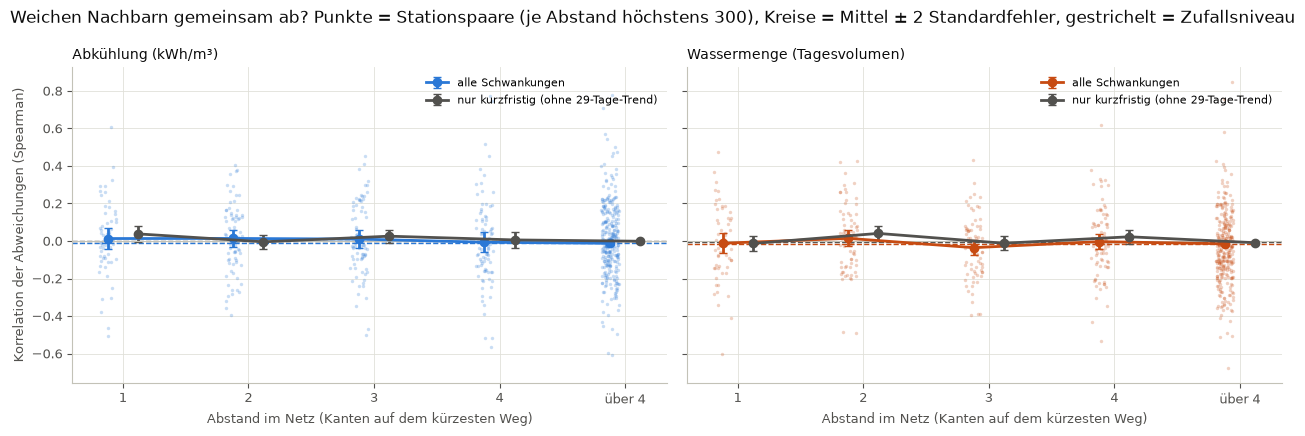

In [21]:
klassen_bild = list(range(1, MAX_ABSTAND + 2))
PUNKTE_JE_ABSTAND = 300     # so viele Paare je Abstand werden als Punkte gezeigt (sonst nur ein Klumpen)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, (kanal, titel) in zip(axes, KANAELE.items()):
    for versatz, variante, farbe in [(-0.12, "alle", FARBE_KANAL[kanal]), (0.12, "kurz", TINTE_LEISE)]:
        g = paare[(paare["kanal"] == kanal) & (paare["variante"] == variante) & (paare["klasse"] >= 1)]
        if variante == "alle":
            punkte = g.sample(frac=1, random_state=SEED).groupby("klasse").head(PUNKTE_JE_ABSTAND)
            ax.scatter(punkte["klasse"] + versatz + rng_netz.uniform(-0.07, 0.07, len(punkte)), punkte["r"],
                       s=6, color=farbe, alpha=0.25, linewidths=0)
        mittel = g.groupby("klasse")["r"].agg(["mean", "sem"]).reindex(klassen_bild)
        ax.errorbar(np.array(klassen_bild) + versatz, mittel["mean"], yerr=2 * mittel["sem"],
                    color=farbe, marker="o", markersize=6, linewidth=2, capsize=3, label=VARIANTEN[variante])
        ax.axhline(test.at[(kanal, variante), "r Zufall"], color=farbe, linestyle="--", linewidth=1)
    ax.axhline(0, color=ACHSE, linewidth=0.8)
    ax.set_xticks(klassen_bild, [KLASSEN_NAME[k] for k in klassen_bild])
    ax.set_xlabel("Abstand im Netz (Kanten auf dem kürzesten Weg)", fontsize=9, color=TINTE_LEISE)
    ax.set_title(titel, loc="left", fontsize=10, color=TINTE)
    ax.legend(frameon=False, fontsize=8, loc="upper right")
    stil(ax)
axes[0].set_ylabel("Korrelation der Abweichungen (Spearman)", fontsize=9, color=TINTE_LEISE)
fig.suptitle(f"Weichen Nachbarn gemeinsam ab? Punkte = Stationspaare (je Abstand höchstens {PUNKTE_JE_ABSTAND}), "
             "Kreise = Mittel ± 2 Standardfehler, gestrichelt = Zufallsniveau", x=0.01, ha="left", color=TINTE)
fig.tight_layout()
plt.show()

**Wie man das Bild liest**
- Je Kanal ein Feld. Farbig = alle Schwankungen, grau = nur kurzfristige. Kreise = mittlere Korrelation je
  Abstand, gestrichelt = Zufallsniveau aus dem Permutationstest.
- **Abstand 1 klar über der gestrichelten Linie, p unter 0,05:** Nachbarn weichen gemeinsam ab, und das Netz
  trägt Information.
- **Kurve fällt mit dem Abstand:** Der Effekt läuft durch das Netz und wird schwächer, wie man es von einem
  Strang erwartet. Ist sie ab Abstand 2 oder 3 auf Zufallsniveau, reichen in einem GNN zwei Schichten.
- **Nur farbig über Zufall, grau nicht:** Gemeinsam sind eher langsame Trends als Tagesschwankungen.
- **Alles auf Zufallsniveau:** Nachbarn tragen nichts bei. Ein GNN wird dann kaum besser als dasselbe Modell
  ohne Kanten.

**Grenzen**
- **Netz oder Lage?** Nachbarn im Netz sind auch Nachbarn auf der Karte (gleiche Sonne, gleiche Bauzeit der
  Straße). Der Test trennt das nicht. Dafür bräuchte man Paare, die nah beieinander liegen, aber im Netz weit
  auseinander (Koordinaten aus Notebook 31).
- **Paare sind nicht unabhängig:** Eine Station steckt in mehreren Paaren. Der Permutationstest berücksichtigt
  das, die Fehlerbalken im Bild nicht. Sie sind nur zur Orientierung.
- **Wenige Paare:** Es gibt nur so viele Paare mit Abstand 1, wie die erste Tabelle unter „Nachbarpaare“
  ausweist. Ein schwacher Effekt kann darin untergehen.

### Ergebnis

- **Nachbarn gegen Zufall:** Bei Abkühlung und Wassermenge weichen direkte Nachbarn (57 Paare) nicht stärker
  gemeinsam ab als zufällige Paare. Alle Schwankungen: r = 0,013 gegen −0,012 (p = 0,17) und −0,012 gegen −0,014
  (p = 0,46). Nur die kurzfristigen Schwankungen der Abkühlung liegen am oberen Rand des Zufallsbereichs (0,038,
  p = 0,028). Bei vier Tests ist das kein belastbarer Befund (Bonferroni-Schwelle 0,0125).
- **Verlauf über den Abstand:** Die Korrelation fällt nicht mit dem Abstand. Alle Mittel liegen zwischen −0,04 und
  0,04, also auf Zufallsniveau.
- **Folgerung für das GNN:** Abkühlung und Wassermenge zeigen keinen Netz-Effekt. Ein GNN auf diesen Größen wird kaum
  besser als dasselbe Modell ohne Kanten. Notebook 39 bestätigt das.

## 16 Zusatz: Vorlauftemperatur und Lage im Netz

**Wozu:** Abschnitt 15 fand für Abkühlung und Wassermenge keinen Netz-Effekt. Hier folgen zwei Fragen, bei
denen das Netz physikalisch am ehesten eine Rolle spielt. Ist auch hier nichts, spielt das Netz für das
Verhalten der Stationen keine messbare Rolle, und ein GNN lohnt sich nicht.

Voraussetzung: Abschnitt 15 ist gelaufen (Netz, Zuordnung und Parameter kommen von dort).

**Test 1 · Schwankt der Vorlauf bei Nachbarn gemeinsam?**
- Der Vorlauf fällt entlang eines Strangs, und wenn viele Häuser gleichzeitig ziehen, kommt hinten weniger an.
  Wenn das Netz irgendwo sichtbar ist, dann hier.
- `vorlauf_c` aus Notebook 10 ist mengengewichtet (Gewicht = Durchfluss der Momentaufnahme). Stehendes Wasser in der
  Leitung verfälscht ihn deshalb kaum.
- Rechnung wie in Abschnitt 15: je Tag Flottenmedian abziehen, Spearman je Paar, Permutationstest, beide
  Varianten.
- Dabei sind alle Stationen mit Heiztagen und Node, nicht nur die überwachten. Eine Referenz braucht es hier nicht.

**Test 3 · Erklärt die Lage im Netz, warum manche Stationen dauerhaft schlechter sind?**
- Je Station ein **Niveau** aus der Zeit vor den Begehungen:
  - **Normkennzahl Referenz** (Abschnitt 12): Abkühlung bei 5 °C im Referenzjahr
  - **Anteil des schlechtesten Tagestyps** aus Notebook 10 (Dauerdurchfluss, wie in Abschnitt 12)
- Je Station die **Lage**, ohne Richtung der Kanten (deren Bedeutung ist noch offen):
  - **Randlage:** mittlerer Abstand zu allen Nodes im Netz, groß = am Rand
  - **Strangende:** Node mit nur einer Kante
- Je Niveau drei Fragen:
  - Sind Nachbarn ähnlich? (Rangabstand, Permutationstest)
  - Hängt es mit der Randlage zusammen? (Spearman)
  - Unterscheiden sich Strangenden vom Rest? (Mann-Whitney)

**Vorab festgelegt: 8 Haupttests**
- Test 1: 2 Varianten. Test 3: 3 Fragen × 2 Niveaus = 6.
- **Bonferroni:** Ein Test zählt erst bei p < 0,05 / 8 = 0,0063. Bei 8 Versuchen ist sonst ein Zufallstreffer
  zu erwarten.
- Keine Varianten nachschieben, bis etwas signifikant wird. Alles, was hier nicht steht, ist explorativ.

**Plausibilitätsprüfung (kein Haupttest):** dieselben drei Fragen für das **Vorlauf-Niveau** einer Station (Median
ihres Abstands zum Flottenmedian).
- Entlang eines Strangs sollte sich der Vorlauf nur langsam ändern, Nachbarn sollten also ähnliche Niveaus haben.
- Zeigt sich davon nichts, bilden die Kanten aus `Nodes_Edges.ods` die Leitungen womöglich nicht gut ab. Dann
  wäre ein „nein“ in den Haupttests wenig wert.
- Die Randlage misst den Abstand zur **Mitte** des Netzes, nicht zum Erzeuger (der kommt in den Kanten nicht
  vor, den bestätigten Erzeuger nutzt erst Notebook 32). Für den Vorlauf ist deshalb vor allem „Nachbarn ähnlich“ aussagekräftig.

In [22]:
# --- Parameter nur fuer diesen Abschnitt (Netz, Varianten und Permutationen aus Abschnitt 15) ---
MIN_TAGE_NIVEAU = 60        # Heiztage je Station, damit ein Niveau (Vorlauf, Typ-Anteil) zaehlt
ALPHA = 0.05                # wird durch die Zahl der Haupttests geteilt (Bonferroni, siehe oben)

# Stationen: alle mit verwendbaren Heiztagen und Node im Netz, nicht nur die ueberwachten
mit_node = sorted(set(modelltage["zaehler"]) & set(node_je.index))
tage16 = modelltage[modelltage["zaehler"].isin(mit_node)]
if NUR_VOR_BEGEHUNG:
    grenze = tage16["zaehler"].map({z: t[0] - pd.Timedelta(days=ABSTAND_BEGEHUNG) for z, t in termine.items()})
    tage16 = tage16[grenze.isna() | (tage16["datum"] < grenze)]
print(f"Stationen mit Node und Heiztagen: {len(mit_node)} | Stations-Heiztage: {len(tage16)}, "
      f"davon mit Vorlauf: {int(tage16['vorlauf_c'].notna().sum())}")


def abstandsmatrix(liste):
    """Abstand im Netz (Kanten auf dem kuerzesten Weg) fuer alle Paare einer Stationsliste."""
    return np.array([[abstand[node_je[a]].get(node_je[b], np.inf) for b in liste] for a in liste], dtype=float)


def flottenmatrix(spalte, variante="alle"):
    """Spalte als Tabelle Kalendertag x Station, je Tag der Median aller Stationen abgezogen."""
    w = tage16.pivot(index="datum", columns="zaehler", values=spalte).asfreq("D")
    zu_wenige = w.notna().sum(axis=1) < MIN_STATIONEN_JE_TAG
    w = w.sub(w.median(axis=1), axis=0)
    w.loc[zu_wenige] = np.nan
    if variante == "kurz":
        w = w - w.rolling(TREND_TAGE, center=True, min_periods=TREND_TAGE // 4).median()
    return w


def permutationstest(P, D, rng):
    """Mittel einer Paar-Kennzahl P ueber die Nachbarpaare (Abstand 1): echt und bei zufaellig verteilten Stationen.

    P ist so gebaut, dass groesser = aehnlicher heisst. Rueckgabe (echt, Zufallswerte, Zahl der Nachbarpaare).
    """
    o = np.triu_indices(len(D), k=1)
    nb = D[o] == 1
    echt = np.nanmean(P[o][nb])
    zufall = np.empty(N_PERMUTATIONEN)
    for i in range(N_PERMUTATIONEN):
        p = rng.permutation(len(D))
        zufall[i] = np.nanmean(P[np.ix_(p, p)][o][nb])
    return echt, zufall, int(np.isfinite(P[o][nb]).sum())


def p_einseitig(echt, zufall):
    return (1 + (zufall >= echt).sum()) / (1 + len(zufall))


# Test 1: schwankt der Vorlauf bei Nachbarn gemeinsam?
rng16 = np.random.default_rng(SEED)
D16 = abstandsmatrix(mit_node)
oben16 = np.triu_indices(len(mit_node), k=1)
vorlauf_zeilen, vorlauf_teile = [], []
for variante in VARIANTEN:
    M = (flottenmatrix("vorlauf_c", variante)
         .corr(method="spearman", min_periods=MIN_GEMEINSAM)
         .reindex(index=mit_node, columns=mit_node).to_numpy())
    echt, zufall, n = permutationstest(M, D16, rng16)
    vorlauf_zeilen.append({"variante": variante, "Nachbarpaare": n, "r Nachbarn": echt, "r Zufall": zufall.mean(),
                           "Zufall 2,5 %": np.quantile(zufall, 0.025), "Zufall 97,5 %": np.quantile(zufall, 0.975),
                           "p (einseitig)": p_einseitig(echt, zufall)})
    vorlauf_teile.append(pd.DataFrame({"variante": variante, "abstand": D16[oben16], "r": M[oben16]}))

vorlauf_test = pd.DataFrame(vorlauf_zeilen).set_index("variante")
vorlauf_paare = pd.concat(vorlauf_teile, ignore_index=True).dropna(subset=["r"])
vorlauf_paare["klasse"] = vorlauf_paare["abstand"].clip(upper=MAX_ABSTAND + 1).astype(int)

print("\nVorlauf, Nachbarn (Abstand 1) gegen Zufall:")
display(vorlauf_test.rename(index=VARIANTEN).rename_axis("Variante").round(3))
vorlauf_je_abstand = (vorlauf_paare.groupby(["klasse", "variante"])["r"].mean().unstack("variante")
                      .rename(index=KLASSEN_NAME, columns=VARIANTEN))
vorlauf_je_abstand.insert(0, "Paare", vorlauf_paare[vorlauf_paare["variante"] == "alle"]
                          .groupby("klasse").size().rename(KLASSEN_NAME))
vorlauf_je_abstand.index.name = "Abstand im Netz"
vorlauf_je_abstand.columns.name = None
print("Vorlauf, mittlere Korrelation je Abstand:")
display(vorlauf_je_abstand.round(3))

Stationen mit Node und Heiztagen: 84 | Stations-Heiztage: 40052, davon mit Vorlauf: 37232



Vorlauf, Nachbarn (Abstand 1) gegen Zufall:


,Nachbarpaare,r Nachbarn,r Zufall,"Zufall 2,5 %","Zufall 97,5 %",p (einseitig)
Variante,,,,,,
alle Schwankungen,59,0.130,0.037,-0.030,0.104,0.004
nur kurzfristig (ohne 29-Tage-Trend),59,0.126,0.059,0.013,0.107,0.004


Vorlauf, mittlere Korrelation je Abstand:


,Paare,alle Schwankungen,nur kurzfristig (ohne 29-Tage-Trend)
Abstand im Netz,,,
gleicher Node,1,0.966,0.856
1,59,0.130,0.126
2,76,0.080,0.098
3,78,0.139,0.132
4,86,0.068,0.096
über 4,2908,0.030,0.054


**Was macht die Zelle?**
- wählt alle Stationen mit Node und verwendbaren Heiztagen und davon die Tage bis kurz vor der ersten Begehung
  (wie in Abschnitt 15)
- `abstandsmatrix()`, `flottenmatrix()`, `permutationstest()` sind dieselben Rechenschritte wie in Abschnitt 15,
  hier als Funktionen, damit Test 1 und Test 3 sie teilen
- **Test 1:** Korrelation des Vorlaufs je Paar und Permutationstest, je Variante
- die zwei Tabellen sind wie in Abschnitt 15 aufgebaut, nur für den Vorlauf

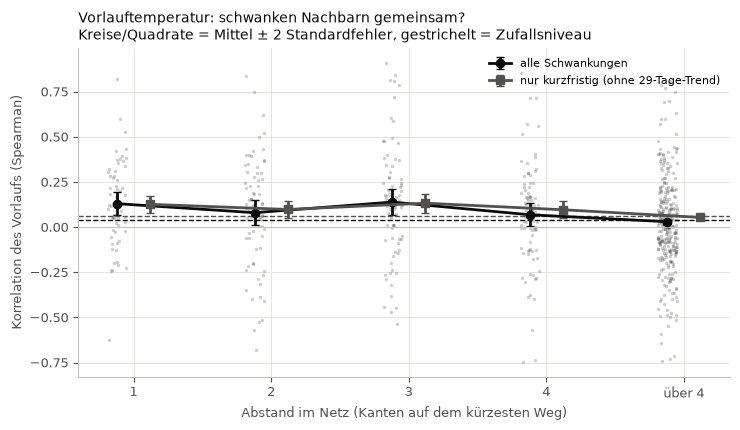

In [23]:
fig, ax = plt.subplots(figsize=(7.5, 4.4))
for versatz, variante, farbe in [(-0.12, "alle", TINTE), (0.12, "kurz", TINTE_LEISE)]:
    g = vorlauf_paare[(vorlauf_paare["variante"] == variante) & (vorlauf_paare["klasse"] >= 1)]
    if variante == "alle":
        punkte = g.sample(frac=1, random_state=SEED).groupby("klasse").head(PUNKTE_JE_ABSTAND)
        ax.scatter(punkte["klasse"] + versatz + rng16.uniform(-0.07, 0.07, len(punkte)), punkte["r"],
                   s=6, color=farbe, alpha=0.2, linewidths=0)
    mittel = g.groupby("klasse")["r"].agg(["mean", "sem"]).reindex(klassen_bild)
    ax.errorbar(np.array(klassen_bild) + versatz, mittel["mean"], yerr=2 * mittel["sem"], color=farbe,
                marker="o" if variante == "alle" else "s", markersize=6, linewidth=2, capsize=3,
                label=VARIANTEN[variante])
    ax.axhline(vorlauf_test.at[variante, "r Zufall"], color=farbe, linestyle="--", linewidth=1)
ax.axhline(0, color=ACHSE, linewidth=0.8)
ax.set_xticks(klassen_bild, [KLASSEN_NAME[k] for k in klassen_bild])
ax.set_xlabel("Abstand im Netz (Kanten auf dem kürzesten Weg)", fontsize=9, color=TINTE_LEISE)
ax.set_ylabel("Korrelation des Vorlaufs (Spearman)", fontsize=9, color=TINTE_LEISE)
ax.set_title("Vorlauftemperatur: schwanken Nachbarn gemeinsam?\n"
             "Kreise/Quadrate = Mittel ± 2 Standardfehler, gestrichelt = Zufallsniveau",
             loc="left", fontsize=10, color=TINTE)
ax.legend(frameon=False, fontsize=8, loc="upper right")
stil(ax)
fig.tight_layout()
plt.show()

**Wie man das Bild liest**
- wie in Abschnitt 15: dunkel = alle Schwankungen, grau = nur kurzfristige, gestrichelt = Zufallsniveau
- **Abstand 1 über der gestrichelten Linie und Kurve fällt mit dem Abstand:** Der Vorlauf läuft durch das Netz,
  Nachbarn bekommen gemeinsam mehr oder weniger Temperatur.
- **flach auf Zufallsniveau:** Auch der Vorlauf zeigt keine Kopplung zwischen Nachbarn.

In [24]:
# Lage jedes Nodes im Netz (ohne Richtung)
mittlerer_abstand = {n: np.mean([d for m, d in abstand[n].items() if m != n]) for n in netz.nodes}
grad = dict(netz.degree)
lage = pd.DataFrame({"node": node_je})
lage["randlage"] = lage["node"].map(mittlerer_abstand)    # mittlerer Abstand zu allen Nodes, gross = am Rand
lage["strangende"] = lage["node"].map(grad) == 1

# Niveau je Station, alles aus der Zeit vor den Begehungen
ziele = {}
ziele["norm_referenz"] = ("Normkennzahl Referenz", "Haupttest",
                          flotte.set_index("zaehler")["norm_referenz"])
if "cluster" in tage16.columns and tage16["cluster"].notna().any():
    heiz_alle = tage[tage["heiztag"] & tage["cluster"].notna()]
    schlechtester16 = heiz_alle.groupby("cluster")["kwh_pro_m3"].median().idxmin()   # wie Abschnitt 12
    g = tage16[tage16["cluster"].notna()].groupby("zaehler")["cluster"]
    ziele["typ_anteil"] = (f"Anteil Tagestyp {schlechtester16}", "Haupttest",
                           g.apply(lambda c: (c == schlechtester16).mean())[g.size() >= MIN_TAGE_NIVEAU])
else:
    print("hast_tage.csv enthaelt keine Clusterspalte - Typ-Anteil entfaellt")
w = flottenmatrix("vorlauf_c")
ziele["vorlauf_niveau"] = ("Vorlauf-Niveau (K zur Flotte)", "Plausibilität",
                           w.median()[w.notna().sum() >= MIN_TAGE_NIVEAU])

# Test 3: erklaert die Lage das Niveau? Je Ziel drei Fragen
zeilen16, rang_teile = [], []
for ziel, (name, rolle, werte) in ziele.items():
    liste = [z for z in werte.dropna().index if z in lage.index]
    v = werte.reindex(liste)
    D = abstandsmatrix(liste)
    rang = v.rank(pct=True).to_numpy()
    P = -np.abs(rang[:, None] - rang[None, :])          # minus Rangabstand: groesser = aehnlicher
    echt, zufall, n_paare = permutationstest(P, D, rng16)
    zeilen16.append({"Frage": "Nachbarn ähnlich (Rangabstand)", "Größe": name, "Rolle": rolle,
                     "n": f"{n_paare} Paare", "echt": -echt, "Vergleich": -zufall.mean(),
                     "p": p_einseitig(echt, zufall)})
    o = np.triu_indices(len(liste), k=1)
    rang_teile.append(pd.DataFrame({"ziel": ziel, "abstand": D[o], "rangabstand": -P[o]}))

    rho, p = stats.spearmanr(lage.loc[liste, "randlage"], v)
    zeilen16.append({"Frage": "Randlage (Spearman ρ)", "Größe": name, "Rolle": rolle,
                     "n": f"{len(liste)} Stationen", "echt": rho, "Vergleich": 0.0, "p": p})

    ende = lage.loc[liste, "strangende"].to_numpy()
    p = stats.mannwhitneyu(v[ende], v[~ende], alternative="two-sided").pvalue if ende.any() and (~ende).any() else np.nan
    zeilen16.append({"Frage": "Strangende (Median Ende − übrige)", "Größe": name, "Rolle": rolle,
                     "n": f"{int(ende.sum())} / {int((~ende).sum())} Stationen",
                     "echt": v[ende].median() - v[~ende].median(), "Vergleich": 0.0, "p": p})

# Alle Tests des Abschnitts in einer Tabelle, Haupttests mit Bonferroni-Schwelle
test1 = [{"Frage": "Vorlauf gemeinsam (r Nachbarn)", "Größe": VARIANTEN[variante], "Rolle": "Haupttest",
          "n": f"{int(z['Nachbarpaare'])} Paare", "echt": z["r Nachbarn"], "Vergleich": z["r Zufall"],
          "p": z["p (einseitig)"]} for variante, z in vorlauf_test.iterrows()]
tests16 = pd.DataFrame(test1 + zeilen16)
n_haupt = int((tests16["Rolle"] == "Haupttest").sum())
schwelle = ALPHA / n_haupt
tests16["unter Schwelle"] = np.where(tests16["Rolle"] == "Haupttest",
                                     np.where(tests16["p"] < schwelle, "ja", "nein"), "–")
print(f"{n_haupt} Haupttests, Bonferroni-Schwelle {ALPHA} / {n_haupt} = {schwelle:.4f}")
print("Vergleich = Zufallsniveau (Permutation) bzw. 0; Rangabstand: 0 = gleich, 1/3 = typisch zufällig")
display(tests16.round(3))

rang_paare = pd.concat(rang_teile, ignore_index=True)
rang_paare["klasse"] = rang_paare["abstand"].clip(upper=MAX_ABSTAND + 1).astype(int)
rang_je_abstand = (rang_paare.groupby(["klasse", "ziel"])["rangabstand"].mean().unstack("ziel")
                   .rename(index=KLASSEN_NAME, columns={k: v[0] for k, v in ziele.items()}))
rang_je_abstand.index.name = "Abstand im Netz"
rang_je_abstand.columns.name = None
print("Mittlerer Rangabstand je Abstand im Netz (kleiner = ähnlicher):")
display(rang_je_abstand.round(3))

8 Haupttests, Bonferroni-Schwelle 0.05 / 8 = 0.0063
Vergleich = Zufallsniveau (Permutation) bzw. 0; Rangabstand: 0 = gleich, 1/3 = typisch zufällig


,Frage,Größe,Rolle,n,echt,Vergleich,p,unter Schwelle
0,Vorlauf gemeinsam (r Nachbarn),alle Schwankungen,Haupttest,59 Paare,0.130,0.037,0.004,ja
1,Vorlauf gemeinsam (r Nachbarn),nur kurzfristig (ohne 29-Tage-Trend),Haupttest,59 Paare,0.126,0.059,0.004,ja
2,Nachbarn ähnlich (Rangabstand),Normkennzahl Referenz,Haupttest,58 Paare,0.339,0.338,0.497,nein
3,Randlage (Spearman ρ),Normkennzahl Referenz,Haupttest,80 Stationen,-0.177,0.000,0.116,nein
4,Strangende (Median Ende − übrige),Normkennzahl Referenz,Haupttest,15 / 65 Stationen,-2.326,0.000,0.482,nein
5,Nachbarn ähnlich (Rangabstand),Anteil Tagestyp D,Haupttest,56 Paare,0.258,0.265,0.428,nein
6,Randlage (Spearman ρ),Anteil Tagestyp D,Haupttest,80 Stationen,-0.009,0.000,0.936,nein
7,Strangende (Median Ende − übrige),Anteil Tagestyp D,Haupttest,15 / 65 Stationen,0.000,0.000,0.895,nein
8,Nachbarn ähnlich (Rangabstand),Vorlauf-Niveau (K zur Flotte),Plausibilität,60 Paare,0.223,0.338,0.000,–
9,Randlage (Spearman ρ),Vorlauf-Niveau (K zur Flotte),Plausibilität,82 Stationen,-0.495,0.000,0.000,–


Mittlerer Rangabstand je Abstand im Netz (kleiner = ähnlicher):


,Normkennzahl Referenz,Anteil Tagestyp D,Vorlauf-Niveau (K zur Flotte)
Abstand im Netz,,,
gleicher Node,NaN,0.050,0.012
1,0.339,0.258,0.223
2,0.335,0.257,0.274
3,0.344,0.243,0.256
4,0.333,0.262,0.283
über 4,0.338,0.266,0.345


**Was macht die Zelle?**
- berechnet die Lage je Node (Randlage, Strangende) und das Niveau je Station, alles aus der Zeit vor den
  Begehungen
- Die Normkennzahl gibt es nur für die überwachten Stationen (sie braucht eine Referenz). Typ-Anteil und
  Vorlauf-Niveau gibt es für alle Stationen mit mindestens 60 Heiztagen.
- **Rangabstand:** Die Stationen werden nach ihrem Niveau in eine Rangliste von 0 bis 1 gebracht. Der Abstand
  zweier Stationen in dieser Liste liegt bei zufälliger Verteilung im Mittel bei 1/3, kleiner heißt ähnlicher.
  Ränge statt Werte, damit einzelne Ausreißer nicht dominieren.
- **erste Tabelle:** alle Tests des Abschnitts, 8 Haupttests und 3 zur Plausibilität
  - `echt` = gemessen, `Vergleich` = Zufallsniveau aus den Permutationen bzw. 0
  - `unter Schwelle` gibt es nur für Haupttests (Bonferroni)
- **zweite Tabelle:** mittlerer Rangabstand je Abstand im Netz. Steigt er mit dem Abstand, ändern sich die
  Niveaus entlang des Netzes langsam.

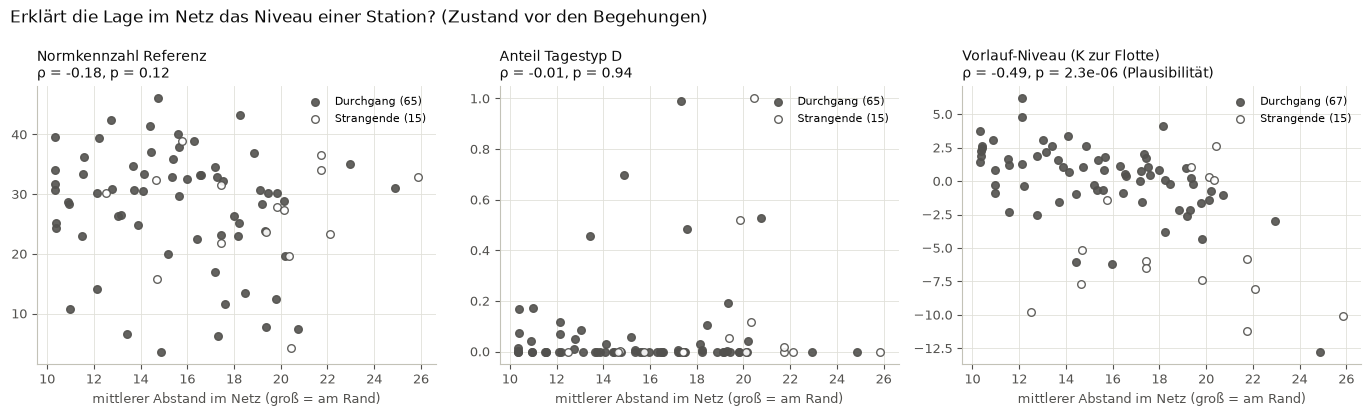

In [25]:
fig, axes = plt.subplots(1, len(ziele), figsize=(4.6 * len(ziele), 4.2))
for ax, (ziel, (name, rolle, werte)) in zip(np.atleast_1d(axes), ziele.items()):
    d = lage.join(werte.rename("wert"), how="inner").dropna(subset=["wert"])
    for ende, fuellung, label in [(False, TINTE_LEISE, "Durchgang"), (True, "white", "Strangende")]:
        g = d[d["strangende"] == ende]
        ax.scatter(g["randlage"], g["wert"], s=30, facecolor=fuellung, edgecolor=TINTE_LEISE, linewidths=1,
                   alpha=0.9, label=f"{label} ({len(g)})")
    z = tests16[(tests16["Größe"] == name) & (tests16["Frage"].str.startswith("Randlage"))].iloc[0]
    ax.set_title(f"{name}\nρ = {z['echt']:+.2f}, p = {z['p']:.2g}" + (" (Plausibilität)" if rolle != "Haupttest" else ""),
                 loc="left", fontsize=10, color=TINTE)
    ax.set_xlabel("mittlerer Abstand im Netz (groß = am Rand)", fontsize=9, color=TINTE_LEISE)
    ax.legend(frameon=False, fontsize=8)
    stil(ax)
fig.suptitle("Erklärt die Lage im Netz das Niveau einer Station? (Zustand vor den Begehungen)",
             x=0.01, ha="left", color=TINTE)
fig.tight_layout()
plt.show()

**Wie man das Bild liest**
- je Niveau ein Feld: x = Randlage, y = Niveau; gefüllt = Durchgang, hohl = Strangende
- **Normkennzahl:** Liegen die Punkte rechts tiefer, kühlen Stationen am Rand schlechter aus.
- **Typ-Anteil:** Liegen sie rechts höher, haben Stationen am Rand mehr Dauerdurchfluss-Tage.
- **Vorlauf-Niveau:** Liegen sie rechts tiefer, kommt am Rand weniger Temperatur an. Das gilt nur, wenn der
  Einspeisepunkt eher in der Mitte liegt.

**Was das Ergebnis für das GNN heißt**

| Ergebnis | Folgerung |
|---|---|
| Test 1 ja | Das Netz koppelt die Stationen im Tagesverlauf. Nächster Schritt: das Nachbarmittel des Vorlaufs als Einflussgröße in die Kennlinie (Abschnitt 5), noch kein GNN |
| Test 3 ja bei Randlage oder Strangende | Die Lage erklärt das Niveau. Lage-Merkmale als feste Merkmale je Station reichen, dafür braucht es kein GNN |
| Test 3 ja nur bei „Nachbarn ähnlich“ | Die Nachbarschaft trägt Information, die die einfachen Lage-Maße nicht fassen. Nur in diesem Fall verspricht ein GNN echten Mehrwert |
| alles nein | Das Netz spielt für das Verhalten der Stationen keine messbare Rolle. GNN fallen lassen |
| Plausibilität nein | Erst die Kanten mit der ÜZ prüfen, bevor man aus einem „nein“ etwas schließt |

**Grenzen**
- **Netz oder Karte?** Wie in Abschnitt 15: Nachbarn im Netz sind auch räumliche Nachbarn.
- **Randlage ≠ Abstand zum Erzeuger.** Der Einspeisepunkt steht nicht in den Kanten.
- **Das Niveau hängt vor allem am Gebäude** (Größe, Nutzung, Heizungsanlage). Die Lage kann davon nur einen Teil
  erklären. Ein kleiner, aber echter Effekt kann bei rund 80 Stationen unter der Bonferroni-Schwelle bleiben.

### Ergebnis

- **Test 1 (Vorlauf gemeinsam):** ja. Direkte Nachbarn (59 Paare) schwanken beim Vorlauf gemeinsam: r = 0,130 gegen
  0,037 bei Zufall (alle Schwankungen) und 0,126 gegen 0,059 (nur kurzfristig), beide p = 0,004 und damit unter der
  Bonferroni-Schwelle 0,0063. Bis Abstand 4 liegt die Korrelation über dem Wert weit entfernter Paare (0,03), sie
  fällt aber nicht gleichmäßig.
- **Test 3 (Lage und Niveau):** nein. Weder die Normkennzahl noch der Anteil des Tagestyps D hängen mit
  Nachbarschaft, Randlage oder Strangende zusammen (alle p über 0,1).
- **Plausibilität (Vorlauf-Niveau):** Nachbarn haben ähnliche Vorlauf-Niveaus (Rangabstand 0,223 gegen 0,338 bei
  Zufall). Am Rand ist der Vorlauf niedriger (ρ = −0,50), an Strangenden im Median um 6,6 K. Die Kanten bilden die
  Leitungen also brauchbar ab, das „nein“ in Test 3 ist aussagekräftig.
- **Folgerung für das GNN:** Das Netz koppelt nur den Vorlauf, nicht Abkühlung, Wassermenge oder das Niveau einer
  Station. Den Vorlauf misst jede Station selbst. Nach der Tabelle oben spricht das gegen ein GNN, und Notebook 39
  findet entsprechend keinen messbaren Gewinn.

## Zusammenfassung & Bewertung

**Ergebnis**
- 89 von 93 Stationen werden überwacht. Die Wassermenge hängt klar am Wetter (Skill 0,26), die Abkühlung kaum (Skill 0,02).
- 479 Alarme in 133 Stationsjahren = 3,6 je Station und Jahr, weniger als beim Kennlinienmonitor (knapp 5), aber mehr als die Theorie erwarten lässt.
- Ventilfall 68956351: Abkühlungs-Alarm 2 Tage nach dem Stellmotortausch, aber kein Wassermengen-Alarm und schon vorher 4 Alarme.
- Wetterbereinigte Wirkung (DiD): Abkühlung +1,11 kWh/m³ (p = 0,20), Wassermenge −11,2 % (p = 0,026); bei mechanischen Befunden größer (+1,86 kWh/m³, −13,8 %).
- Alarme im Fenster um die Begehung: einer der beiden Kanäle 30 von 43 gegen 0,53 Kontrollquote, Hebel 1,33, p = 0,017.

**Belastbar**
- Die Wassermenge ist der brauchbare Kanal: Temperatur verbessert die Vorhersage bei 85 % der Stationen, 83 % der Alarme nach Begehungen zeigen in Richtung Verbesserung.
- Die Normkennzahl bei 5 °C passt zu den Tagestypen aus Notebook 10 (rho = −0,64, n = 84) und liefert eine Liste dauerhaft schwacher Stationen, die der Alarm allein nicht findet.
- Prüfung mit Kontrollgruppe am selben Datum statt Zufallsbasis; der Herbsteffekt ist damit berücksichtigt.

**Schwach**
- Abkühlungskanal: Die Kennlinie bringt auf neuen Tagen kaum etwas, und nur 41 % der Abkühlungs-Treffer zeigen in Richtung Verbesserung. Der hohe Hebel (1,77) ist deshalb vorsichtig zu lesen.
- Bei mechanischen Befunden ist die Wirkung größer, die Abkühlungs-Treffer aber nicht signifikant (14 Fälle). Abschnitt 10 und 11 passen hier nicht zusammen.
- Wenige, nicht unabhängige Fälle (43 auswertbare Termine), Schwellen gesetzt statt hergeleitet, p-Werte eher zu optimistisch.
- Die Alarmrate liegt deutlich über der Theorie; die Autokorrelation (Median 0,59 bis 0,68) ist nur näherungsweise korrigiert.

**Offen**
- Häufen sich die Alarme jeden Herbst? Das Monatsbild in Abschnitt 9 ist nicht in Zahlen ausgewertet.
- Passt die Geradenform für die Abkühlung? Die Steigung (−0,32 je K) ist nur halb so steil wie in Notebook 05; das Formbild in Abschnitt 2 ist nicht in Zahlen ausgewertet.
- Warum trifft die Abkühlung bei nicht mechanischen Begehungen besser, obwohl dort die Wirkung kleiner ist?

### Ergänzung aus den Abschnitten 15 und 16

- Die Abschnitte 15 und 16 sind Vortests für das GNN (Notebook 39) und stammen aus einer späteren Arbeitsfassung
  dieses Notebooks. Sie brauchen die Netztabellen aus Notebook 31.
- Bei Abkühlung und Wassermenge weichen Nachbarn im Netz nicht gemeinsam ab (p = 0,17 und 0,46). Nur der Vorlauf
  schwankt bei Nachbarn gemeinsam (r = 0,13 gegen 0,04, p = 0,004).
- Die Lage im Netz erklärt nicht, warum manche Stationen dauerhaft schlechter abkühlen.
- Folgerung: Die Fehler, die dieses Modell sucht, sitzen im einzelnen Haus. Ein GNN verspricht hier keinen Gewinn.